In [1]:
import math
import random
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment initialized successfully.")
print("Random seed:", SEED)

Environment initialized successfully.
Random seed: 42


In [2]:
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

DATA_PATH = "../data/processed.cleveland.data"

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print("===== DATASET SHAPE =====")
print(df.shape)

print("\n===== COLUMN NAMES =====")
print(df.columns.tolist())

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== TARGET CLASS DISTRIBUTION =====")
print(df["num"].value_counts().sort_index())

===== DATASET SHAPE =====
(303, 14)

===== COLUMN NAMES =====
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

===== DATA TYPES =====
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

===== MISSING VALUES =====
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

===== TARGET CLASS DISTRIBUTION =====
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [4]:
FEATURES = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

TARGET = "num"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Number of input features:", len(FEATURES))
print("Input features:", FEATURES)
print("Target:", TARGET)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nIs target inside X?", TARGET in X.columns)

Number of input features: 13
Input features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target: num

X shape: (303, 13)
y shape: (303,)

Is target inside X? False


In [5]:
CONTINUOUS_FEATURES = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

CATEGORICAL_FEATURES = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Continuous features:")
print(CONTINUOUS_FEATURES)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

print("\nTotal features:",
      len(CONTINUOUS_FEATURES) + len(CATEGORICAL_FEATURES))

Continuous features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Total features: 13


In [6]:
def create_stratified_folds(y, n_folds=5, seed=42):
    """
    Create stratified folds so that each fold has a similar
    class distribution to the complete dataset.
    """

    rng = np.random.default_rng(seed)

    folds = [[] for _ in range(n_folds)]

    # Process each class separately
    for class_label in sorted(y.unique()):
        indices = np.where(y.to_numpy() == class_label)[0]

        # Shuffle indices within this class
        rng.shuffle(indices)

        # Distribute them across folds
        for i, index in enumerate(indices):
            folds[i % n_folds].append(index)

    # Sort indices inside each fold for deterministic ordering
    folds = [np.array(sorted(fold)) for fold in folds]

    return folds


folds = create_stratified_folds(y, n_folds=5, seed=SEED)

print("Number of folds:", len(folds))

for i, fold in enumerate(folds, start=1):
    print(f"\nFold {i}")
    print("Number of patients:", len(fold))
    print("Class distribution:")
    print(y.iloc[fold].value_counts().sort_index())

Number of folds: 5

Fold 1
Number of patients: 62
Class distribution:
num
0    33
1    11
2     8
3     7
4     3
Name: count, dtype: int64

Fold 2
Number of patients: 61
Class distribution:
num
0    33
1    11
2     7
3     7
4     3
Name: count, dtype: int64

Fold 3
Number of patients: 61
Class distribution:
num
0    33
1    11
2     7
3     7
4     3
Name: count, dtype: int64

Fold 4
Number of patients: 60
Class distribution:
num
0    33
1    11
2     7
3     7
4     2
Name: count, dtype: int64

Fold 5
Number of patients: 59
Class distribution:
num
0    32
1    11
2     7
3     7
4     2
Name: count, dtype: int64


In [7]:
N_BINS = 5


def fit_equal_width_binning(data, features, n_bins=5):
    """
    Learn equal-width bin boundaries from training data only.
    Returns a dictionary containing the learned boundaries.
    """
    
    binning_info = {}

    for feature in features:
        values = data[feature].dropna().astype(float)

        min_value = values.min()
        max_value = values.max()

        # Create equally spaced boundaries
        boundaries = np.linspace(
            min_value,
            max_value,
            n_bins + 1
        )

        binning_info[feature] = boundaries

    return binning_info


def apply_equal_width_binning(data, binning_info):
    result = data.copy()

    for feature, boundaries in binning_info.items():
        values = result[feature].astype(float)

        # Keep values within the range learned from training data.
        values = values.clip(
            lower=boundaries[0],
            upper=boundaries[-1]
        )

        result[feature] = pd.cut(
            values,
            bins=boundaries,
            labels=False,
            include_lowest=True
        )

    return result

In [8]:
# Use Fold 1 as the held-out fold
test_indices = folds[0]

# All other folds are used for training
train_indices = np.concatenate(folds[1:])

train_data = df.iloc[train_indices].copy()
test_data = df.iloc[test_indices].copy()

# Learn equal-width bin boundaries ONLY from training data
equal_width_bins = fit_equal_width_binning(
    train_data,
    CONTINUOUS_FEATURES,
    n_bins=N_BINS
)

print("Equal-width bin boundaries learned from training data:\n")

for feature, boundaries in equal_width_bins.items():
    print(f"{feature}:")
    print(boundaries)
    print()

Equal-width bin boundaries learned from training data:

age:
[29.  38.6 48.2 57.8 67.4 77. ]

trestbps:
[ 94.  115.2 136.4 157.6 178.8 200. ]

chol:
[126.  213.6 301.2 388.8 476.4 564. ]

thalach:
[ 71.   97.2 123.4 149.6 175.8 202. ]

oldpeak:
[0.   1.24 2.48 3.72 4.96 6.2 ]



In [9]:
# Apply the learned equal-width bins to the training and test data
train_binned = apply_equal_width_binning(
    train_data,
    equal_width_bins
)

test_binned = apply_equal_width_binning(
    test_data,
    equal_width_bins
)

print("Original training data:")
print(train_data[CONTINUOUS_FEATURES].head())

print("\nBinned training data:")
print(train_binned[CONTINUOUS_FEATURES].head())

Original training data:
     age  trestbps   chol  thalach  oldpeak
2   67.0     120.0  229.0    129.0      2.6
6   62.0     140.0  268.0    160.0      3.6
14  52.0     172.0  199.0    162.0      0.5
15  57.0     150.0  168.0    174.0      1.6
22  58.0     120.0  284.0    160.0      1.8

Binned training data:
    age  trestbps  chol  thalach  oldpeak
2     3         1     1        2        2
6     3         2     1        3        2
14    2         3     0        3        0
15    2         2     0        3        1
22    3         1     1        3        1


In [10]:
def fill_missing_values(data):
    """
    Replace missing values with the explicit categorical value 'missing'.
    This allows missingness to become a feature-value token later.
    """
    result = data.copy()

    for feature in FEATURES:
        if result[feature].isnull().any():
            result[feature] = result[feature].fillna("missing")

    return result


train_with_missing = fill_missing_values(train_binned)
test_with_missing = fill_missing_values(test_binned)

print("Missing values in training data after processing:")
print(train_with_missing[FEATURES].isnull().sum())

print("\nMissing values in test data after processing:")
print(test_with_missing[FEATURES].isnull().sum())

print("\nExamples of missing values:")
print(
    train_with_missing[
        train_with_missing["ca"].astype(str) == "missing"
    ][["ca", "thal", "num"]]
)

print(
    train_with_missing[
        train_with_missing["thal"].astype(str) == "missing"
    ][["ca", "thal", "num"]]
)

Missing values in training data after processing:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Missing values in test data after processing:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Examples of missing values:
          ca thal  num
166  missing  3.0    0
192  missing  7.0    1
302  missing  3.0    0
      ca     thal  num
266  0.0  missing    2
87   0.0  missing    0


In [11]:
def row_to_tokens(row):
    """
    Convert one processed patient row into a list of
    feature-value tokens.

    Continuous features have '_bin' in their token name.
    Categorical features retain their original names.
    Missing values are represented explicitly as 'missing'.
    """

    tokens = []

    # Continuous features → binned tokens
    for feature in CONTINUOUS_FEATURES:
        value = row[feature]

        if pd.isna(value):
            value = "missing"
        else:
            value = int(value)

        tokens.append(f"{feature}_bin={value}")

    # Categorical features → categorical tokens
    for feature in CATEGORICAL_FEATURES:
        value = row[feature]

        if pd.isna(value):
            value = "missing"
        elif isinstance(value, (float, np.floating)):
            value = int(value)

        tokens.append(f"{feature}={value}")

    return tokens

In [12]:
# Take the first patient from the training data
example_patient = train_with_missing.iloc[0]

# Convert the patient into feature-value tokens
example_tokens = row_to_tokens(example_patient)

print("Example patient:")
print(example_patient[FEATURES])

print("\nTokens:")
for token in example_tokens:
    print(token)

print("\nNumber of tokens:", len(example_tokens))

Example patient:
age           3
sex         1.0
cp          4.0
trestbps      1
chol          1
fbs         0.0
restecg     2.0
thalach       2
exang       1.0
oldpeak       2
slope       2.0
ca          2.0
thal        7.0
Name: 2, dtype: object

Tokens:
age_bin=3
trestbps_bin=1
chol_bin=1
thalach_bin=2
oldpeak_bin=2
sex=1
cp=4
fbs=0
restecg=2
exang=1
slope=2
ca=2
thal=7

Number of tokens: 13


In [13]:
def build_vocabulary(data):
    """
    Build a vocabulary containing every unique feature-value
    token appearing in the training data.
    """

    vocabulary = set()

    for _, row in data.iterrows():
        tokens = row_to_tokens(row)
        vocabulary.update(tokens)

    return sorted(vocabulary)


vocabulary = build_vocabulary(train_with_missing)

print("Vocabulary size:", len(vocabulary))

print("\nFirst 30 vocabulary tokens:")
for token in vocabulary[:30]:
    print(token)

Vocabulary size: 50

First 30 vocabulary tokens:
age_bin=0
age_bin=1
age_bin=2
age_bin=3
age_bin=4
ca=0
ca=1
ca=2
ca=3
ca=missing
chol_bin=0
chol_bin=1
chol_bin=2
chol_bin=3
chol_bin=4
cp=1
cp=2
cp=3
cp=4
exang=0
exang=1
fbs=0
fbs=1
oldpeak_bin=0
oldpeak_bin=1
oldpeak_bin=2
oldpeak_bin=3
oldpeak_bin=4
restecg=0
restecg=1


In [14]:
def preprocess_train_test(train_df, test_df, n_bins=5):
    """
    Complete preprocessing pipeline for one train/test split.

    Steps:
    1. Learn equal-width bin boundaries from training data.
    2. Apply those same boundaries to train and test data.
    3. Replace missing values with the explicit 'missing' token.
    4. Convert each patient into feature-value tokens.
    5. Build vocabulary from training tokens only.
    """

    # --------------------------------------------------
    # Step 1: Learn binning thresholds from TRAIN only
    # --------------------------------------------------
    binning_info = fit_equal_width_binning(
        train_df,
        CONTINUOUS_FEATURES,
        n_bins=n_bins
    )

    # --------------------------------------------------
    # Step 2: Apply the SAME thresholds to both datasets
    # --------------------------------------------------
    train_processed = apply_equal_width_binning(
        train_df,
        binning_info
    )

    test_processed = apply_equal_width_binning(
        test_df,
        binning_info
    )

    # --------------------------------------------------
    # Step 3: Handle missing values explicitly
    # --------------------------------------------------
    train_processed = fill_missing_values(train_processed)
    test_processed = fill_missing_values(test_processed)

    # --------------------------------------------------
    # Step 4: Convert rows into tokens
    # --------------------------------------------------
    train_tokens = [
        row_to_tokens(row)
        for _, row in train_processed.iterrows()
    ]

    test_tokens = [
        row_to_tokens(row)
        for _, row in test_processed.iterrows()
    ]

    # --------------------------------------------------
    # Step 5: Build vocabulary from TRAINING tokens only
    # --------------------------------------------------
    vocabulary = sorted(
        set(token for tokens in train_tokens for token in tokens)
    )

    return (
        train_tokens,
        test_tokens,
        vocabulary,
        binning_info
    )

In [15]:
# Test the complete preprocessing pipeline on Fold 1

test_indices = folds[0]
train_indices = np.concatenate(folds[1:])

train_data = df.iloc[train_indices].copy()
test_data = df.iloc[test_indices].copy()

train_tokens, test_tokens, vocabulary, binning_info = preprocess_train_test(
    train_data,
    test_data,
    n_bins=N_BINS
)

print("===== PREPROCESSING CHECK =====")
print("Training patients:", len(train_tokens))
print("Test patients:", len(test_tokens))
print("Vocabulary size:", len(vocabulary))

print("\nTokens for first training patient:")
print(train_tokens[0])

print("\nTokens for first test patient:")
print(test_tokens[0])

print("\nEqual-width bin boundaries:")
for feature, boundaries in binning_info.items():
    print(f"{feature}: {boundaries}")

===== PREPROCESSING CHECK =====
Training patients: 241
Test patients: 62
Vocabulary size: 50

Tokens for first training patient:
['age_bin=3', 'trestbps_bin=1', 'chol_bin=1', 'thalach_bin=2', 'oldpeak_bin=2', 'sex=1', 'cp=4', 'fbs=0', 'restecg=2', 'exang=1', 'slope=2', 'ca=2', 'thal=7']

Tokens for first test patient:
['age_bin=3', 'trestbps_bin=3', 'chol_bin=1', 'thalach_bin=1', 'oldpeak_bin=1', 'sex=1', 'cp=4', 'fbs=0', 'restecg=2', 'exang=1', 'slope=2', 'ca=3', 'thal=3']

Equal-width bin boundaries:
age: [29.  38.6 48.2 57.8 67.4 77. ]
trestbps: [ 94.  115.2 136.4 157.6 178.8 200. ]
chol: [126.  213.6 301.2 388.8 476.4 564. ]
thalach: [ 71.   97.2 123.4 149.6 175.8 202. ]
oldpeak: [0.   1.24 2.48 3.72 4.96 6.2 ]


In [16]:
def fit_quantile_binning(data, features, n_bins=5):
    """
    Learn quantile-based bin boundaries from training data only.
    """
    binning_info = {}

    for feature in features:
        values = data[feature].dropna().astype(float)

        # Quantile positions: 0%, 20%, 40%, 60%, 80%, 100%
        quantiles = np.linspace(0, 1, n_bins + 1)

        boundaries = np.quantile(values, quantiles)

        # Remove duplicate boundaries caused by repeated values.
        boundaries = np.unique(boundaries)

        binning_info[feature] = boundaries

    return binning_info


def apply_quantile_binning(data, binning_info):
    """
    Apply training-derived quantile boundaries to new data.
    """
    result = data.copy()

    for feature, boundaries in binning_info.items():

        values = result[feature].astype(float)

        # Keep values inside the training-derived range.
        values = values.clip(
            lower=boundaries[0],
            upper=boundaries[-1]
        )

        result[feature] = pd.cut(
            values,
            bins=boundaries,
            labels=False,
            include_lowest=True
        )

    return result

In [17]:
# Learn quantile bins from Fold 1 training data

quantile_bins = fit_quantile_binning(
    train_data,
    CONTINUOUS_FEATURES,
    n_bins=N_BINS
)

print("===== QUANTILE BIN BOUNDARIES =====")

for feature, boundaries in quantile_bins.items():
    print(f"{feature}: {boundaries}")

print("\n===== NUMBER OF ACTUAL BINS =====")

for feature, boundaries in quantile_bins.items():
    print(f"{feature}: {len(boundaries) - 1} bins")

===== QUANTILE BIN BOUNDARIES =====
age: [29. 46. 53. 58. 62. 77.]
trestbps: [ 94. 120. 128. 135. 145. 200.]
chol: [126. 204. 229. 255. 288. 564.]
thalach: [ 71. 132. 147. 160. 169. 202.]
oldpeak: [0.  0.4 1.2 1.9 6.2]

===== NUMBER OF ACTUAL BINS =====
age: 5 bins
trestbps: 5 bins
chol: 5 bins
thalach: 5 bins
oldpeak: 4 bins


In [18]:
# Apply the training-derived quantile bins to Fold 1

train_quantile_binned = apply_quantile_binning(
    train_data,
    quantile_bins
)

test_quantile_binned = apply_quantile_binning(
    test_data,
    quantile_bins
)

print("===== ORIGINAL TRAINING VALUES =====")
print(train_data[CONTINUOUS_FEATURES].head())

print("\n===== QUANTILE-BINNED TRAINING VALUES =====")
print(train_quantile_binned[CONTINUOUS_FEATURES].head())

print("\n===== QUANTILE-BINNED TEST VALUES =====")
print(test_quantile_binned[CONTINUOUS_FEATURES].head())

===== ORIGINAL TRAINING VALUES =====
     age  trestbps   chol  thalach  oldpeak
2   67.0     120.0  229.0    129.0      2.6
6   62.0     140.0  268.0    160.0      3.6
14  52.0     172.0  199.0    162.0      0.5
15  57.0     150.0  168.0    174.0      1.6
22  58.0     120.0  284.0    160.0      1.8

===== QUANTILE-BINNED TRAINING VALUES =====
    age  trestbps  chol  thalach  oldpeak
2     4         0     1        0        3
6     3         3     3        2        3
14    1         4     0        3        1
15    2         4     0        4        2
22    2         0     3        2        2

===== QUANTILE-BINNED TEST VALUES =====
    age  trestbps  chol  thalach  oldpeak
1     4         4     3        0        2
9     1         3     0        2        3
13    0         0     3        4        0
33    3         2     2        3        1
34    0         2     2        4        0


In [19]:
def preprocess_train_test_quantile(train_df, test_df, n_bins=5):
    """
    Complete quantile-binning preprocessing pipeline.

    Steps:
    1. Learn quantile bin boundaries from training data only.
    2. Apply those same boundaries to train and test data.
    3. Replace missing values with the explicit 'missing' token.
    4. Convert each patient into feature-value tokens.
    5. Build vocabulary from training tokens only.
    """

    binning_info = fit_quantile_binning(
        train_df,
        CONTINUOUS_FEATURES,
        n_bins=n_bins
    )

    train_processed = apply_quantile_binning(
        train_df,
        binning_info
    )

    test_processed = apply_quantile_binning(
        test_df,
        binning_info
    )

    train_processed = fill_missing_values(train_processed)
    test_processed = fill_missing_values(test_processed)

    train_tokens = [
        row_to_tokens(row)
        for _, row in train_processed.iterrows()
    ]

    test_tokens = [
        row_to_tokens(row)
        for _, row in test_processed.iterrows()
    ]

    vocabulary = sorted(
        set(token for tokens in train_tokens for token in tokens)
    )

    return train_tokens, test_tokens, vocabulary, binning_info

In [20]:
def train_multinomial_nb(train_tokens, train_labels, vocabulary, alpha=1.0):
    """
    Train a Multinomial Naive Bayes classifier from scratch.

    Parameters:
        train_tokens : list of lists
            Tokens for each training patient.
        train_labels : list
            Class label for each training patient.
        vocabulary : list
            All tokens observed in the training data.
        alpha : float
            Laplace smoothing parameter.

    Returns:
        model : dictionary containing learned probabilities and counts.
    """

    class_counts = Counter(train_labels)
    token_counts = defaultdict(Counter)
    total_token_counts = Counter()

    classes = sorted(class_counts.keys())
    vocabulary_size = len(vocabulary)

    # Count each token inside each class
    for tokens, label in zip(train_tokens, train_labels):
        for token in tokens:
            token_counts[label][token] += 1
            total_token_counts[label] += 1

    # Calculate empirical class priors
    total_patients = len(train_labels)

    class_priors = {
        label: class_counts[label] / total_patients
        for label in classes
    }

    # Calculate smoothed token probabilities
    token_probabilities = {}

    for label in classes:
        denominator = (
            total_token_counts[label]
            + alpha * vocabulary_size
        )

        token_probabilities[label] = {}

        for token in vocabulary:
            numerator = token_counts[label][token] + alpha
            token_probabilities[label][token] = numerator / denominator

    model = {
        "classes": classes,
        "class_counts": class_counts,
        "class_priors": class_priors,
        "token_counts": token_counts,
        "total_token_counts": total_token_counts,
        "token_probabilities": token_probabilities,
        "vocabulary": vocabulary,
        "alpha": alpha
    }

    return model

In [21]:
# Prepare labels for Fold 1
train_labels = train_data[TARGET].astype(int).tolist()
test_labels = test_data[TARGET].astype(int).tolist()

# Train Multinomial Naive Bayes
multinomial_model = train_multinomial_nb(
    train_tokens,
    train_labels,
    vocabulary,
    alpha=1.0
)

print("===== MULTINOMIAL NB TRAINING =====")
print("Classes:", multinomial_model["classes"])
print("Alpha:", multinomial_model["alpha"])
print("Vocabulary size:", len(multinomial_model["vocabulary"]))

print("\nClass counts:")
for label in multinomial_model["classes"]:
    print(
        f"Class {label}: "
        f"{multinomial_model['class_counts'][label]} patients"
    )

print("\nClass priors:")
for label in multinomial_model["classes"]:
    print(
        f"Class {label}: "
        f"{multinomial_model['class_priors'][label]:.6f}"
    )

print("\nTotal tokens per class:")
for label in multinomial_model["classes"]:
    print(
        f"Class {label}: "
        f"{multinomial_model['total_token_counts'][label]}"
    )

===== MULTINOMIAL NB TRAINING =====
Classes: [0, 1, 2, 3, 4]
Alpha: 1.0
Vocabulary size: 50

Class counts:
Class 0: 131 patients
Class 1: 44 patients
Class 2: 28 patients
Class 3: 28 patients
Class 4: 10 patients

Class priors:
Class 0: 0.543568
Class 1: 0.182573
Class 2: 0.116183
Class 3: 0.116183
Class 4: 0.041494

Total tokens per class:
Class 0: 1703
Class 1: 572
Class 2: 364
Class 3: 364
Class 4: 130


In [22]:
def predict_multinomial_nb(model, patient_tokens):
    """
    Predict the class of one patient using Multinomial Naive Bayes.
    """

    scores = {}

    for label in model["classes"]:

        # Start with log prior
        score = math.log(model["class_priors"][label])

        # Add log probability of every patient token
        for token in patient_tokens:
            probability = model["token_probabilities"][label][token]
            score += math.log(probability)

        scores[label] = score

    # Deterministic tie-break:
    # choose the smallest class label if scores are equal.
    predicted_class = min(
        scores,
        key=lambda label: (-scores[label], label)
    )

    return predicted_class, scores

In [23]:
# Predict the first test patient

patient_tokens = test_tokens[0]

prediction, scores = predict_multinomial_nb(
    multinomial_model,
    patient_tokens
)

actual_class = test_labels[0]

print("===== SINGLE PATIENT PREDICTION =====")
print("Patient tokens:")
print(patient_tokens)

print("\nActual class:", actual_class)
print("Predicted class:", prediction)

print("\nLog-posterior scores:")
for label in multinomial_model["classes"]:
    print(f"Class {label}: {scores[label]:.6f}")

===== SINGLE PATIENT PREDICTION =====
Patient tokens:
['age_bin=3', 'trestbps_bin=3', 'chol_bin=1', 'thalach_bin=1', 'oldpeak_bin=1', 'sex=1', 'cp=4', 'fbs=0', 'restecg=2', 'exang=1', 'slope=2', 'ca=3', 'thal=3']

Actual class: 2
Predicted class: 1

Log-posterior scores:
Class 0: -54.216467
Class 1: -48.018087
Class 2: -48.465381
Class 3: -48.107999
Class 4: -49.995785


In [24]:
# Predict every patient in the Fold 1 test set

multinomial_predictions = []

for patient_tokens in test_tokens:
    prediction, _ = predict_multinomial_nb(
        multinomial_model,
        patient_tokens
    )
    multinomial_predictions.append(prediction)

print("===== MULTINOMIAL PREDICTIONS =====")
print("Number of predictions:", len(multinomial_predictions))

print("\nFirst 20 predictions:")
print(multinomial_predictions[:20])

print("\nFirst 20 actual labels:")
print(test_labels[:20])

===== MULTINOMIAL PREDICTIONS =====
Number of predictions: 62

First 20 predictions:
[1, 3, 0, 1, 0, 3, 3, 0, 0, 1, 0, 1, 2, 0, 0, 0, 0, 1, 0, 3]

First 20 actual labels:
[2, 1, 0, 0, 0, 3, 4, 0, 2, 2, 0, 1, 0, 0, 0, 0, 0, 2, 0, 3]


In [25]:
def calculate_confusion_matrix(actual, predicted, classes):
    """
    Create a confusion matrix from scratch.

    Rows    = actual classes
    Columns = predicted classes
    """

    class_to_index = {
        label: i for i, label in enumerate(classes)
    }

    matrix = np.zeros(
        (len(classes), len(classes)),
        dtype=int
    )

    for true_label, predicted_label in zip(actual, predicted):
        true_index = class_to_index[true_label]
        predicted_index = class_to_index[predicted_label]
        matrix[true_index][predicted_index] += 1

    return matrix


def calculate_metrics(actual, predicted, classes):
    """
    Calculate accuracy, precision, recall, F1,
    macro F1 and micro F1 from scratch.
    """

    confusion = calculate_confusion_matrix(
        actual,
        predicted,
        classes
    )

    total = confusion.sum()
    correct = np.trace(confusion)

    accuracy = correct / total

    precision = {}
    recall = {}
    f1 = {}

    for i, label in enumerate(classes):

        tp = confusion[i, i]
        fp = confusion[:, i].sum() - tp
        fn = confusion[i, :].sum() - tp

        if tp + fp == 0:
            precision[label] = 0.0
        else:
            precision[label] = tp / (tp + fp)

        if tp + fn == 0:
            recall[label] = 0.0
        else:
            recall[label] = tp / (tp + fn)

        if precision[label] + recall[label] == 0:
            f1[label] = 0.0
        else:
            f1[label] = (
                2 * precision[label] * recall[label]
                / (precision[label] + recall[label])
            )

    macro_f1 = np.mean([
        f1[label] for label in classes
    ])

    # Micro-averaged quantities
    total_tp = np.trace(confusion)

    total_fp = (
        confusion.sum(axis=0).sum()
        - total_tp
    )

    total_fn = (
        confusion.sum(axis=1).sum()
        - total_tp
    )

    micro_precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0.0
    )

    micro_recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0.0
    )

    micro_f1 = (
        2 * micro_precision * micro_recall
        / (micro_precision + micro_recall)
        if micro_precision + micro_recall > 0 else 0.0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "confusion_matrix": confusion
    }

In [26]:
multinomial_metrics = calculate_metrics(
    test_labels,
    multinomial_predictions,
    multinomial_model["classes"]
)

print("===== MULTINOMIAL NB — FOLD 1 =====")

print(f"Accuracy : {multinomial_metrics['accuracy']:.4f}")
print(f"Macro F1 : {multinomial_metrics['macro_f1']:.4f}")
print(f"Micro F1 : {multinomial_metrics['micro_f1']:.4f}")

print("\nClass-wise metrics:")
print("Class     Precision    Recall       F1")

for label in multinomial_model["classes"]:
    print(
        f"{label:<9}"
        f"{multinomial_metrics['precision'][label]:.4f}       "
        f"{multinomial_metrics['recall'][label]:.4f}       "
        f"{multinomial_metrics['f1'][label]:.4f}"
    )

print("\nConfusion Matrix:")
print(multinomial_metrics["confusion_matrix"])

===== MULTINOMIAL NB — FOLD 1 =====
Accuracy : 0.5161
Macro F1 : 0.3014
Micro F1 : 0.5161

Class-wise metrics:
Class     Precision    Recall       F1
0        0.7429       0.7879       0.7647
1        0.1429       0.1818       0.1600
2        0.2000       0.1250       0.1538
3        0.4286       0.4286       0.4286
4        0.0000       0.0000       0.0000

Confusion Matrix:
[[26  5  1  0  1]
 [ 8  2  0  1  0]
 [ 1  4  1  2  0]
 [ 0  2  2  3  0]
 [ 0  1  1  1  0]]


In [27]:
def train_bernoulli_nb(train_tokens, train_labels, vocabulary, alpha=1.0):
    """
    Train a Multivariate Bernoulli Naive Bayes classifier
    from scratch.

    Each vocabulary token is treated as a binary event:
        1 = present in patient
        0 = absent from patient
    """

    class_counts = Counter(train_labels)
    classes = sorted(class_counts.keys())

    total_patients = len(train_labels)
    vocabulary_size = len(vocabulary)

    # Count how many patients in each class contain each token.
    token_presence_counts = defaultdict(Counter)

    for tokens, label in zip(train_tokens, train_labels):

        # Set removes duplicates and makes the representation
        # explicitly binary: present or absent.
        present_tokens = set(tokens)

        for token in present_tokens:
            token_presence_counts[label][token] += 1

    # Empirical class priors
    class_priors = {
        label: class_counts[label] / total_patients
        for label in classes
    }

    # Smoothed probability that each token is PRESENT
    token_presence_probabilities = {}

    for label in classes:

        denominator = class_counts[label] + 2 * alpha

        token_presence_probabilities[label] = {}

        for token in vocabulary:
            numerator = (
                token_presence_counts[label][token]
                + alpha
            )

            token_presence_probabilities[label][token] = (
                numerator / denominator
            )

    model = {
        "classes": classes,
        "class_counts": class_counts,
        "class_priors": class_priors,
        "token_presence_counts": token_presence_counts,
        "token_presence_probabilities":
            token_presence_probabilities,
        "vocabulary": vocabulary,
        "alpha": alpha
    }

    return model

In [28]:
bernoulli_model = train_bernoulli_nb(
    train_tokens,
    train_labels,
    vocabulary,
    alpha=1.0
)

print("===== BERNOULLI NB TRAINING =====")
print("Classes:", bernoulli_model["classes"])
print("Alpha:", bernoulli_model["alpha"])
print("Vocabulary size:", len(bernoulli_model["vocabulary"]))

print("\nClass counts:")
for label in bernoulli_model["classes"]:
    print(
        f"Class {label}: "
        f"{bernoulli_model['class_counts'][label]} patients"
    )

print("\nClass priors:")
for label in bernoulli_model["classes"]:
    print(
        f"Class {label}: "
        f"{bernoulli_model['class_priors'][label]:.6f}"
    )

print("\nExample token probabilities:")
example_tokens = [
    "cp=4",
    "sex=1",
    "thal=3"
]

for token in example_tokens:
    print(f"\n{token}:")
    for label in bernoulli_model["classes"]:
        probability = (
            bernoulli_model["token_presence_probabilities"]
            [label][token]
        )
        print(f"  Class {label}: {probability:.6f}")

===== BERNOULLI NB TRAINING =====
Classes: [0, 1, 2, 3, 4]
Alpha: 1.0
Vocabulary size: 50

Class counts:
Class 0: 131 patients
Class 1: 44 patients
Class 2: 28 patients
Class 3: 28 patients
Class 4: 10 patients

Class priors:
Class 0: 0.543568
Class 1: 0.182573
Class 2: 0.116183
Class 3: 0.116183
Class 4: 0.041494

Example token probabilities:

cp=4:
  Class 0: 0.255639
  Class 1: 0.695652
  Class 2: 0.800000
  Class 3: 0.766667
  Class 4: 0.833333

sex=1:
  Class 0: 0.541353
  Class 1: 0.826087
  Class 2: 0.866667
  Class 3: 0.733333
  Class 4: 0.833333

thal=3:
  Class 0: 0.796992
  Class 1: 0.347826
  Class 2: 0.166667
  Class 3: 0.200000
  Class 4: 0.166667


In [29]:
def predict_bernoulli_nb(model, patient_tokens):
    """
    Predict the class of one patient using Multivariate
    Bernoulli Naive Bayes.

    Both present and absent vocabulary tokens are included.
    """

    scores = {}

    # Convert patient's tokens to a set for binary presence/absence.
    patient_token_set = set(patient_tokens)

    for label in model["classes"]:

        # Start with log prior.
        score = math.log(model["class_priors"][label])

        # Consider EVERY token in the vocabulary.
        for token in model["vocabulary"]:

            probability_present = (
                model["token_presence_probabilities"]
                [label][token]
            )

            if token in patient_token_set:
                # Token is PRESENT
                score += math.log(probability_present)

            else:
                # Token is ABSENT
                score += math.log(1.0 - probability_present)

        scores[label] = score

    # Deterministic tie-break:
    # choose smallest class label if scores are equal.
    predicted_class = min(
        scores,
        key=lambda label: (-scores[label], label)
    )

    return predicted_class, scores

In [30]:
# Predict every patient in the Fold 1 test set

bernoulli_predictions = []

for patient_tokens in test_tokens:
    prediction, _ = predict_bernoulli_nb(
        bernoulli_model,
        patient_tokens
    )
    bernoulli_predictions.append(prediction)

print("===== BERNOULLI PREDICTIONS =====")
print("Number of predictions:", len(bernoulli_predictions))

print("\nFirst 20 predictions:")
print(bernoulli_predictions[:20])

print("\nFirst 20 actual labels:")
print(test_labels[:20])

===== BERNOULLI PREDICTIONS =====
Number of predictions: 62

First 20 predictions:
[1, 3, 0, 1, 0, 3, 3, 0, 0, 1, 0, 1, 2, 0, 0, 0, 0, 1, 0, 1]

First 20 actual labels:
[2, 1, 0, 0, 0, 3, 4, 0, 2, 2, 0, 1, 0, 0, 0, 0, 0, 2, 0, 3]


In [31]:
bernoulli_metrics = calculate_metrics(
    test_labels,
    bernoulli_predictions,
    bernoulli_model["classes"]
)

print("===== BERNOULLI NB — FOLD 1 =====")

print(f"Accuracy : {bernoulli_metrics['accuracy']:.4f}")
print(f"Macro F1 : {bernoulli_metrics['macro_f1']:.4f}")
print(f"Micro F1 : {bernoulli_metrics['micro_f1']:.4f}")

print("\nClass-wise metrics:")
print("Class     Precision    Recall       F1")

for label in bernoulli_model["classes"]:
    print(
        f"{label:<9}"
        f"{bernoulli_metrics['precision'][label]:.4f}       "
        f"{bernoulli_metrics['recall'][label]:.4f}       "
        f"{bernoulli_metrics['f1'][label]:.4f}"
    )

print("\nConfusion Matrix:")
print(bernoulli_metrics["confusion_matrix"])

===== BERNOULLI NB — FOLD 1 =====
Accuracy : 0.5000
Macro F1 : 0.2772
Micro F1 : 0.5000

Class-wise metrics:
Class     Precision    Recall       F1
0        0.7429       0.7879       0.7647
1        0.1429       0.1818       0.1600
2        0.2000       0.1250       0.1538
3        0.3333       0.2857       0.3077
4        0.0000       0.0000       0.0000

Confusion Matrix:
[[26  5  1  0  1]
 [ 8  2  0  1  0]
 [ 1  4  1  2  0]
 [ 0  2  2  2  1]
 [ 0  1  1  1  0]]


In [32]:
def run_multinomial_cv(df, folds, binning_strategy="equal_width",
                       n_bins=5, alpha=1.0):

    fold_results = []

    for fold_number in range(len(folds)):

        test_indices = folds[fold_number]
        train_indices = np.concatenate(
            [folds[i] for i in range(len(folds))
             if i != fold_number]
        )

        train_df = df.iloc[train_indices].copy()
        test_df = df.iloc[test_indices].copy()

        # Preprocess using training data only
        if binning_strategy == "equal_width":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        elif binning_strategy == "quantile":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test_quantile(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        else:
            raise ValueError(
                "binning_strategy must be "
                "'equal_width' or 'quantile'"
            )

        train_labels = train_df[TARGET].astype(int).tolist()
        test_labels = test_df[TARGET].astype(int).tolist()

        # Train model
        model = train_multinomial_nb(
            train_tokens,
            train_labels,
            vocabulary,
            alpha=alpha
        )

        # Predict
        predictions = []

        for tokens in test_tokens:
            prediction, _ = predict_multinomial_nb(
                model,
                tokens
            )
            predictions.append(prediction)

        # Evaluate
        metrics = calculate_metrics(
            test_labels,
            predictions,
            model["classes"]
        )

        fold_results.append({
            "fold": fold_number + 1,
            "accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"],
            "micro_f1": metrics["micro_f1"],
            "confusion_matrix": metrics["confusion_matrix"]
        })

    return fold_results

In [33]:
multinomial_cv_results = run_multinomial_cv(
    df,
    folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== 5-FOLD MULTINOMIAL NB — EQUAL WIDTH =====")

for result in multinomial_cv_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

print("\n===== AVERAGE =====")

average_accuracy = np.mean([
    result["accuracy"]
    for result in multinomial_cv_results
])

average_macro_f1 = np.mean([
    result["macro_f1"]
    for result in multinomial_cv_results
])

average_micro_f1 = np.mean([
    result["micro_f1"]
    for result in multinomial_cv_results
])

print(f"Average Accuracy : {average_accuracy:.4f}")
print(f"Average Macro F1 : {average_macro_f1:.4f}")
print(f"Average Micro F1 : {average_micro_f1:.4f}")

===== 5-FOLD MULTINOMIAL NB — EQUAL WIDTH =====
Fold 1: Accuracy = 0.5161, Macro F1 = 0.3014, Micro F1 = 0.5161
Fold 2: Accuracy = 0.5902, Macro F1 = 0.3786, Micro F1 = 0.5902
Fold 3: Accuracy = 0.6393, Macro F1 = 0.4834, Micro F1 = 0.6393
Fold 4: Accuracy = 0.6500, Macro F1 = 0.4168, Micro F1 = 0.6500
Fold 5: Accuracy = 0.5593, Macro F1 = 0.2848, Micro F1 = 0.5593

===== AVERAGE =====
Average Accuracy : 0.5910
Average Macro F1 : 0.3730
Average Micro F1 : 0.5910


In [34]:
def run_bernoulli_cv(df, folds, binning_strategy="equal_width",
                     n_bins=5, alpha=1.0):

    fold_results = []

    for fold_number in range(len(folds)):

        test_indices = folds[fold_number]

        train_indices = np.concatenate(
            [folds[i] for i in range(len(folds))
             if i != fold_number]
        )

        train_df = df.iloc[train_indices].copy()
        test_df = df.iloc[test_indices].copy()

        # Preprocess using training data only
        if binning_strategy == "equal_width":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        elif binning_strategy == "quantile":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test_quantile(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        else:
            raise ValueError(
                "binning_strategy must be "
                "'equal_width' or 'quantile'"
            )

        train_labels = train_df[TARGET].astype(int).tolist()
        test_labels = test_df[TARGET].astype(int).tolist()

        # Train Bernoulli model
        model = train_bernoulli_nb(
            train_tokens,
            train_labels,
            vocabulary,
            alpha=alpha
        )

        # Predict
        predictions = []

        for tokens in test_tokens:
            prediction, _ = predict_bernoulli_nb(
                model,
                tokens
            )
            predictions.append(prediction)

        # Evaluate
        metrics = calculate_metrics(
            test_labels,
            predictions,
            model["classes"]
        )

        fold_results.append({
            "fold": fold_number + 1,
            "accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"],
            "micro_f1": metrics["micro_f1"],
            "confusion_matrix": metrics["confusion_matrix"]
        })

    return fold_results

In [35]:
bernoulli_cv_results = run_bernoulli_cv(
    df,
    folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== 5-FOLD BERNOULLI NB — EQUAL WIDTH =====")

for result in bernoulli_cv_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

print("\n===== AVERAGE =====")

average_accuracy = np.mean([
    result["accuracy"]
    for result in bernoulli_cv_results
])

average_macro_f1 = np.mean([
    result["macro_f1"]
    for result in bernoulli_cv_results
])

average_micro_f1 = np.mean([
    result["micro_f1"]
    for result in bernoulli_cv_results
])

print(f"Average Accuracy : {average_accuracy:.4f}")
print(f"Average Macro F1 : {average_macro_f1:.4f}")
print(f"Average Micro F1 : {average_micro_f1:.4f}")

===== 5-FOLD BERNOULLI NB — EQUAL WIDTH =====
Fold 1: Accuracy = 0.5000, Macro F1 = 0.2772, Micro F1 = 0.5000
Fold 2: Accuracy = 0.5902, Macro F1 = 0.3929, Micro F1 = 0.5902
Fold 3: Accuracy = 0.6066, Macro F1 = 0.3513, Micro F1 = 0.6066
Fold 4: Accuracy = 0.6333, Macro F1 = 0.4234, Micro F1 = 0.6333
Fold 5: Accuracy = 0.5424, Macro F1 = 0.2900, Micro F1 = 0.5424

===== AVERAGE =====
Average Accuracy : 0.5745
Average Macro F1 : 0.3470
Average Micro F1 : 0.5745


In [36]:
multinomial_quantile_results = run_multinomial_cv(
    df,
    folds,
    binning_strategy="quantile",
    n_bins=5,
    alpha=1.0
)

print("===== 5-FOLD MULTINOMIAL NB — QUANTILE =====")

for result in multinomial_quantile_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

print("\n===== AVERAGE =====")

quantile_accuracy = np.mean([
    result["accuracy"]
    for result in multinomial_quantile_results
])

quantile_macro_f1 = np.mean([
    result["macro_f1"]
    for result in multinomial_quantile_results
])

quantile_micro_f1 = np.mean([
    result["micro_f1"]
    for result in multinomial_quantile_results
])

print(f"Average Accuracy : {quantile_accuracy:.4f}")
print(f"Average Macro F1 : {quantile_macro_f1:.4f}")
print(f"Average Micro F1 : {quantile_micro_f1:.4f}")

===== 5-FOLD MULTINOMIAL NB — QUANTILE =====
Fold 1: Accuracy = 0.5161, Macro F1 = 0.2860, Micro F1 = 0.5161
Fold 2: Accuracy = 0.5574, Macro F1 = 0.2741, Micro F1 = 0.5574
Fold 3: Accuracy = 0.6230, Macro F1 = 0.3660, Micro F1 = 0.6230
Fold 4: Accuracy = 0.5667, Macro F1 = 0.2831, Micro F1 = 0.5667
Fold 5: Accuracy = 0.5424, Macro F1 = 0.3108, Micro F1 = 0.5424

===== AVERAGE =====
Average Accuracy : 0.5611
Average Macro F1 : 0.3040
Average Micro F1 : 0.5611


In [37]:
bernoulli_quantile_results = run_bernoulli_cv(
    df,
    folds,
    binning_strategy="quantile",
    n_bins=5,
    alpha=1.0
)

print("===== 5-FOLD BERNOULLI NB — QUANTILE =====")

for result in bernoulli_quantile_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

print("\n===== AVERAGE =====")

quantile_bernoulli_accuracy = np.mean([
    result["accuracy"]
    for result in bernoulli_quantile_results
])

quantile_bernoulli_macro_f1 = np.mean([
    result["macro_f1"]
    for result in bernoulli_quantile_results
])

quantile_bernoulli_micro_f1 = np.mean([
    result["micro_f1"]
    for result in bernoulli_quantile_results
])

print(
    f"Average Accuracy : "
    f"{quantile_bernoulli_accuracy:.4f}"
)

print(
    f"Average Macro F1 : "
    f"{quantile_bernoulli_macro_f1:.4f}"
)

print(
    f"Average Micro F1 : "
    f"{quantile_bernoulli_micro_f1:.4f}"
)

===== 5-FOLD BERNOULLI NB — QUANTILE =====
Fold 1: Accuracy = 0.5161, Macro F1 = 0.3034, Micro F1 = 0.5161
Fold 2: Accuracy = 0.5902, Macro F1 = 0.3270, Micro F1 = 0.5902
Fold 3: Accuracy = 0.5902, Macro F1 = 0.3526, Micro F1 = 0.5902
Fold 4: Accuracy = 0.6167, Macro F1 = 0.4139, Micro F1 = 0.6167
Fold 5: Accuracy = 0.5424, Macro F1 = 0.3310, Micro F1 = 0.5424

===== AVERAGE =====
Average Accuracy : 0.5711
Average Macro F1 : 0.3456
Average Micro F1 : 0.5711


In [38]:
changed_patients = []

for fold_number in range(len(folds)):

    test_indices = folds[fold_number]

    train_indices = np.concatenate(
        [folds[i] for i in range(len(folds))
         if i != fold_number]
    )

    train_df = df.iloc[train_indices].copy()
    test_df = df.iloc[test_indices].copy()

    # -----------------------------
    # Equal-width preprocessing
    # -----------------------------
    ew_train_tokens, ew_test_tokens, ew_vocab, ew_bins = (
        preprocess_train_test(
            train_df,
            test_df,
            n_bins=5
        )
    )

    ew_model = train_multinomial_nb(
        ew_train_tokens,
        train_df[TARGET].astype(int).tolist(),
        ew_vocab,
        alpha=1.0
    )

    # -----------------------------
    # Quantile preprocessing
    # -----------------------------
    q_train_tokens, q_test_tokens, q_vocab, q_bins = (
        preprocess_train_test_quantile(
            train_df,
            test_df,
            n_bins=5
        )
    )

    q_model = train_multinomial_nb(
        q_train_tokens,
        train_df[TARGET].astype(int).tolist(),
        q_vocab,
        alpha=1.0
    )

    # -----------------------------
    # Compare predictions
    # -----------------------------
    for local_index in range(len(test_indices)):

        ew_prediction, _ = predict_multinomial_nb(
            ew_model,
            ew_test_tokens[local_index]
        )

        q_prediction, _ = predict_multinomial_nb(
            q_model,
            q_test_tokens[local_index]
        )

        if ew_prediction != q_prediction:

            original_index = test_indices[local_index]

            changed_patients.append({
                "fold": fold_number + 1,
                "index": int(original_index),
                "actual": int(test_df.iloc[local_index][TARGET]),
                "equal_width_prediction": ew_prediction,
                "quantile_prediction": q_prediction
            })

print("===== PATIENTS WITH CHANGED PREDICTIONS =====")
print("Number of changed predictions:", len(changed_patients))

print("\nFirst 10 examples:")

for patient in changed_patients[:10]:
    print(patient)

===== PATIENTS WITH CHANGED PREDICTIONS =====
Number of changed predictions: 50

First 10 examples:
{'fold': 1, 'index': 1, 'actual': 2, 'equal_width_prediction': 1, 'quantile_prediction': 3}
{'fold': 1, 'index': 36, 'actual': 3, 'equal_width_prediction': 3, 'quantile_prediction': 1}
{'fold': 1, 'index': 73, 'actual': 1, 'equal_width_prediction': 1, 'quantile_prediction': 2}
{'fold': 1, 'index': 114, 'actual': 2, 'equal_width_prediction': 1, 'quantile_prediction': 3}
{'fold': 1, 'index': 131, 'actual': 0, 'equal_width_prediction': 1, 'quantile_prediction': 0}
{'fold': 1, 'index': 154, 'actual': 3, 'equal_width_prediction': 1, 'quantile_prediction': 2}
{'fold': 1, 'index': 183, 'actual': 0, 'equal_width_prediction': 4, 'quantile_prediction': 1}
{'fold': 1, 'index': 191, 'actual': 3, 'equal_width_prediction': 2, 'quantile_prediction': 4}
{'fold': 1, 'index': 231, 'actual': 2, 'equal_width_prediction': 3, 'quantile_prediction': 4}
{'fold': 1, 'index': 272, 'actual': 2, 'equal_width_predic

In [39]:
patient_index = 131

patient = df.iloc[patient_index]

print("===== PATIENT WHO CHANGED PREDICTION =====")
print("Original dataset index:", patient_index)

print("\nOriginal patient data:")
print(patient)

# Find which fold contains this patient
patient_fold = None

for fold_number, fold_indices in enumerate(folds):
    if patient_index in fold_indices:
        patient_fold = fold_number
        break

print("\nHeld-out fold:", patient_fold + 1)

# Recreate that fold's train/test split
test_indices = folds[patient_fold]

train_indices = np.concatenate(
    [folds[i] for i in range(len(folds))
     if i != patient_fold]
)

train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

# Equal-width
ew_train_tokens, ew_test_tokens, ew_vocab, ew_bins = (
    preprocess_train_test(
        train_df,
        test_df,
        n_bins=5
    )
)

# Quantile
q_train_tokens, q_test_tokens, q_vocab, q_bins = (
    preprocess_train_test_quantile(
        train_df,
        test_df,
        n_bins=5
    )
)

# Locate patient inside the held-out fold
local_position = np.where(
    test_indices == patient_index
)[0][0]

ew_tokens = ew_test_tokens[local_position]
q_tokens = q_test_tokens[local_position]

ew_model = train_multinomial_nb(
    ew_train_tokens,
    train_df[TARGET].astype(int).tolist(),
    ew_vocab,
    alpha=1.0
)

q_model = train_multinomial_nb(
    q_train_tokens,
    train_df[TARGET].astype(int).tolist(),
    q_vocab,
    alpha=1.0
)

ew_prediction, ew_scores = predict_multinomial_nb(
    ew_model,
    ew_tokens
)

q_prediction, q_scores = predict_multinomial_nb(
    q_model,
    q_tokens
)

print("\n===== EQUAL-WIDTH =====")
print("Tokens:")
print(ew_tokens)
print("Prediction:", ew_prediction)

print("\nLog scores:")
for label in ew_model["classes"]:
    print(f"Class {label}: {ew_scores[label]:.6f}")

print("\n===== QUANTILE =====")
print("Tokens:")
print(q_tokens)
print("Prediction:", q_prediction)

print("\nLog scores:")
for label in q_model["classes"]:
    print(f"Class {label}: {q_scores[label]:.6f}")

===== PATIENT WHO CHANGED PREDICTION =====
Original dataset index: 131

Original patient data:
age          51.0
sex           1.0
cp            3.0
trestbps     94.0
chol        227.0
fbs           0.0
restecg       0.0
thalach     154.0
exang         1.0
oldpeak       0.0
slope         1.0
ca            1.0
thal          7.0
num           0.0
Name: 131, dtype: float64

Held-out fold: 1

===== EQUAL-WIDTH =====
Tokens:
['age_bin=2', 'trestbps_bin=0', 'chol_bin=1', 'thalach_bin=3', 'oldpeak_bin=0', 'sex=1', 'cp=3', 'fbs=0', 'restecg=0', 'exang=1', 'slope=1', 'ca=1', 'thal=7']
Prediction: 1

Log scores:
Class 0: -46.942326
Class 1: -46.850849
Class 2: -49.152252
Class 3: -49.058057
Class 4: -52.351614

===== QUANTILE =====
Tokens:
['age_bin=1', 'trestbps_bin=0', 'chol_bin=1', 'thalach_bin=2', 'oldpeak_bin=0', 'sex=1', 'cp=3', 'fbs=0', 'restecg=0', 'exang=1', 'slope=1', 'ca=1', 'thal=7']
Prediction: 0

Log scores:
Class 0: -48.615210
Class 1: -49.488407
Class 2: -52.301467
Class 3: -51.5

In [40]:
print("===== MISSING-VALUE ANALYSIS =====")

missing_rows = df[FEATURES].isnull().any(axis=1)

print("Total patients:", len(df))
print("Patients with at least one missing feature:",
      missing_rows.sum())
print("Complete patients:", (~missing_rows).sum())

print("\nMissing values by feature:")
for feature in FEATURES:
    count = df[feature].isnull().sum()
    if count > 0:
        print(f"{feature}: {count}")

print("\nRows containing missing values:")
print(df.loc[missing_rows, FEATURES + [TARGET]])

===== MISSING-VALUE ANALYSIS =====
Total patients: 303
Patients with at least one missing feature: 6
Complete patients: 297

Missing values by feature:
ca: 4
thal: 2

Rows containing missing values:
      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca  thal  num  
87     1.0  0.0   NaN    0  
166    1.0  NaN   3.0    0  
192    2.0  NaN   7.0    1  
266    2.0  0.0   NaN    2  
287    2.0  NaN   7.0    0  
302    1.0  NaN   3.0    0  


In [41]:
# Remove patients with missing values in any input feature

df_complete = df.dropna(subset=FEATURES).copy()

print("===== COMPLETE-CASE DATASET =====")
print("Original number of patients:", len(df))
print("Patients after removing incomplete records:",
      len(df_complete))
print("Patients removed:", len(df) - len(df_complete))

print("\nRemaining missing values:")
print(df_complete[FEATURES].isnull().sum().sum())

print("\nTarget distribution after removal:")
print(
    df_complete[TARGET]
    .value_counts()
    .sort_index()
)

===== COMPLETE-CASE DATASET =====
Original number of patients: 303
Patients after removing incomplete records: 297
Patients removed: 6

Remaining missing values:
0

Target distribution after removal:
num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64


In [42]:
y_complete = df_complete[TARGET].copy()

complete_folds = create_stratified_folds(
    y_complete,
    n_folds=5,
    seed=SEED
)

print("===== COMPLETE-CASE 5-FOLD SPLIT =====")

for i, fold in enumerate(complete_folds):
    fold_labels = y_complete.iloc[fold]

    print(
        f"Fold {i + 1}: "
        f"{len(fold)} patients | "
        f"Class distribution: "
        f"{dict(sorted(Counter(fold_labels).items()))}"
    )

===== COMPLETE-CASE 5-FOLD SPLIT =====
Fold 1: 60 patients | Class distribution: {0: 32, 1: 11, 2: 7, 3: 7, 4: 3}
Fold 2: 60 patients | Class distribution: {0: 32, 1: 11, 2: 7, 3: 7, 4: 3}
Fold 3: 60 patients | Class distribution: {0: 32, 1: 11, 2: 7, 3: 7, 4: 3}
Fold 4: 59 patients | Class distribution: {0: 32, 1: 11, 2: 7, 3: 7, 4: 2}
Fold 5: 58 patients | Class distribution: {0: 32, 1: 10, 2: 7, 3: 7, 4: 2}


In [43]:
complete_multinomial_results = run_multinomial_cv(
    df_complete,
    complete_folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== COMPLETE-CASE MULTINOMIAL NB =====")

for result in complete_multinomial_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

print("\n===== AVERAGE =====")

complete_accuracy = np.mean([
    result["accuracy"]
    for result in complete_multinomial_results
])

complete_macro_f1 = np.mean([
    result["macro_f1"]
    for result in complete_multinomial_results
])

complete_micro_f1 = np.mean([
    result["micro_f1"]
    for result in complete_multinomial_results
])

print(f"Average Accuracy : {complete_accuracy:.4f}")
print(f"Average Macro F1 : {complete_macro_f1:.4f}")
print(f"Average Micro F1 : {complete_micro_f1:.4f}")

===== COMPLETE-CASE MULTINOMIAL NB =====
Fold 1: Accuracy = 0.5500, Macro F1 = 0.3087, Micro F1 = 0.5500
Fold 2: Accuracy = 0.6000, Macro F1 = 0.3986, Micro F1 = 0.6000
Fold 3: Accuracy = 0.5833, Macro F1 = 0.3352, Micro F1 = 0.5833
Fold 4: Accuracy = 0.5424, Macro F1 = 0.2504, Micro F1 = 0.5424
Fold 5: Accuracy = 0.5000, Macro F1 = 0.2267, Micro F1 = 0.5000

===== AVERAGE =====
Average Accuracy : 0.5551
Average Macro F1 : 0.3039
Average Micro F1 : 0.5551


In [44]:
complete_bernoulli_results = run_bernoulli_cv(
    df_complete,
    complete_folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== COMPLETE-CASE BERNOULLI NB =====")

for result in complete_bernoulli_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

complete_bernoulli_accuracy = np.mean(
    [result["accuracy"] for result in complete_bernoulli_results]
)

complete_bernoulli_macro_f1 = np.mean(
    [result["macro_f1"] for result in complete_bernoulli_results]
)

complete_bernoulli_micro_f1 = np.mean(
    [result["micro_f1"] for result in complete_bernoulli_results]
)

print("\n===== AVERAGE =====")
print(f"Average Accuracy : {complete_bernoulli_accuracy:.4f}")
print(f"Average Macro F1 : {complete_bernoulli_macro_f1:.4f}")
print(f"Average Micro F1 : {complete_bernoulli_micro_f1:.4f}")

===== COMPLETE-CASE BERNOULLI NB =====
Fold 1: Accuracy = 0.5500, Macro F1 = 0.3131, Micro F1 = 0.5500
Fold 2: Accuracy = 0.5833, Macro F1 = 0.3766, Micro F1 = 0.5833
Fold 3: Accuracy = 0.5667, Macro F1 = 0.3061, Micro F1 = 0.5667
Fold 4: Accuracy = 0.5763, Macro F1 = 0.3337, Micro F1 = 0.5763
Fold 5: Accuracy = 0.5000, Macro F1 = 0.2234, Micro F1 = 0.5000

===== AVERAGE =====
Average Accuracy : 0.5553
Average Macro F1 : 0.3106
Average Micro F1 : 0.5553


In [45]:
# Convert the original 5-class target into a binary target.
# 0 = no heart disease
# 1 = heart disease present (original classes 1-4)

df_binary = df.copy()

df_binary[TARGET] = df_binary[TARGET].apply(
    lambda label: 0 if label == 0 else 1
)

print("===== BINARY TARGET DISTRIBUTION =====")
print(df_binary[TARGET].value_counts().sort_index())

print("\n===== ORIGINAL 5-CLASS DISTRIBUTION =====")
print(df[TARGET].value_counts().sort_index())

===== BINARY TARGET DISTRIBUTION =====
num
0    164
1    139
Name: count, dtype: int64

===== ORIGINAL 5-CLASS DISTRIBUTION =====
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [46]:
y_binary = df_binary[TARGET].copy()

binary_folds = create_stratified_folds(
    y_binary,
    n_folds=5,
    seed=SEED
)

print("===== BINARY 5-FOLD DISTRIBUTION =====")

for i, fold_indices in enumerate(binary_folds, start=1):
    fold_labels = y_binary.iloc[fold_indices]

    print(
        f"Fold {i}: "
        f"size = {len(fold_indices)}, "
        f"class 0 = {(fold_labels == 0).sum()}, "
        f"class 1 = {(fold_labels == 1).sum()}"
    )

===== BINARY 5-FOLD DISTRIBUTION =====
Fold 1: size = 61, class 0 = 33, class 1 = 28
Fold 2: size = 61, class 0 = 33, class 1 = 28
Fold 3: size = 61, class 0 = 33, class 1 = 28
Fold 4: size = 61, class 0 = 33, class 1 = 28
Fold 5: size = 59, class 0 = 32, class 1 = 27


In [47]:
binary_multinomial_results = run_multinomial_cv(
    df_binary,
    binary_folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== BINARY MULTINOMIAL NB =====")

for result in binary_multinomial_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

binary_multinomial_accuracy = np.mean(
    [result["accuracy"] for result in binary_multinomial_results]
)

binary_multinomial_macro_f1 = np.mean(
    [result["macro_f1"] for result in binary_multinomial_results]
)

binary_multinomial_micro_f1 = np.mean(
    [result["micro_f1"] for result in binary_multinomial_results]
)

print("\n===== AVERAGE =====")
print(f"Average Accuracy : {binary_multinomial_accuracy:.4f}")
print(f"Average Macro F1 : {binary_multinomial_macro_f1:.4f}")
print(f"Average Micro F1 : {binary_multinomial_micro_f1:.4f}")

===== BINARY MULTINOMIAL NB =====
Fold 1: Accuracy = 0.7869, Macro F1 = 0.7860, Micro F1 = 0.7869
Fold 2: Accuracy = 0.8525, Macro F1 = 0.8499, Micro F1 = 0.8525
Fold 3: Accuracy = 0.8197, Macro F1 = 0.8195, Micro F1 = 0.8197
Fold 4: Accuracy = 0.8361, Macro F1 = 0.8324, Micro F1 = 0.8361
Fold 5: Accuracy = 0.8475, Macro F1 = 0.8473, Micro F1 = 0.8475

===== AVERAGE =====
Average Accuracy : 0.8285
Average Macro F1 : 0.8270
Average Micro F1 : 0.8285


In [48]:
binary_bernoulli_results = run_bernoulli_cv(
    df_binary,
    binary_folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== BINARY BERNOULLI NB =====")

for result in binary_bernoulli_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}, "
        f"Micro F1 = {result['micro_f1']:.4f}"
    )

binary_bernoulli_accuracy = np.mean(
    [result["accuracy"] for result in binary_bernoulli_results]
)

binary_bernoulli_macro_f1 = np.mean(
    [result["macro_f1"] for result in binary_bernoulli_results]
)

binary_bernoulli_micro_f1 = np.mean(
    [result["micro_f1"] for result in binary_bernoulli_results]
)

print("\n===== AVERAGE =====")
print(f"Average Accuracy : {binary_bernoulli_accuracy:.4f}")
print(f"Average Macro F1 : {binary_bernoulli_macro_f1:.4f}")
print(f"Average Micro F1 : {binary_bernoulli_micro_f1:.4f}")

===== BINARY BERNOULLI NB =====
Fold 1: Accuracy = 0.8033, Macro F1 = 0.8028, Micro F1 = 0.8033
Fold 2: Accuracy = 0.8525, Macro F1 = 0.8499, Micro F1 = 0.8525
Fold 3: Accuracy = 0.8361, Macro F1 = 0.8357, Micro F1 = 0.8361
Fold 4: Accuracy = 0.8361, Macro F1 = 0.8339, Micro F1 = 0.8361
Fold 5: Accuracy = 0.8475, Macro F1 = 0.8473, Micro F1 = 0.8475

===== AVERAGE =====
Average Accuracy : 0.8351
Average Macro F1 : 0.8339
Average Micro F1 : 0.8351


In [49]:
def predict_multinomial_nb_with_prior(
    model,
    patient_tokens,
    prior_type="empirical"
):
    scores = {}

    number_of_classes = len(model["classes"])

    for label in model["classes"]:

        if prior_type == "empirical":
            prior = model["class_priors"][label]

        elif prior_type == "uniform":
            prior = 1.0 / number_of_classes

        else:
            raise ValueError(
                "prior_type must be 'empirical' or 'uniform'"
            )

        score = math.log(prior)

        for token in patient_tokens:
            probability = model["token_probabilities"][label][token]
            score += math.log(probability)

        scores[label] = score

    predicted_class = min(
        scores,
        key=lambda label: (-scores[label], label)
    )

    return predicted_class, scores

In [50]:
def run_multinomial_prior_cv(
    df,
    folds,
    prior_type="empirical",
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
):
    fold_results = []

    for fold_number in range(len(folds)):

        test_indices = folds[fold_number]

        train_indices = np.concatenate(
            [
                folds[i]
                for i in range(len(folds))
                if i != fold_number
            ]
        )

        train_df = df.iloc[train_indices].copy()
        test_df = df.iloc[test_indices].copy()

        if binning_strategy == "equal_width":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        elif binning_strategy == "quantile":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test_quantile(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        else:
            raise ValueError(
                "Unknown binning strategy"
            )

        train_labels = train_df[TARGET].astype(int).tolist()
        test_labels = test_df[TARGET].astype(int).tolist()

        model = train_multinomial_nb(
            train_tokens,
            train_labels,
            vocabulary,
            alpha=alpha
        )

        predictions = [
            predict_multinomial_nb_with_prior(
                model,
                tokens,
                prior_type=prior_type
            )[0]
            for tokens in test_tokens
        ]

        metrics = calculate_metrics(
            test_labels,
            predictions,
            model["classes"]
        )

        fold_results.append(
            {
                "fold": fold_number + 1,
                "accuracy": metrics["accuracy"],
                "macro_f1": metrics["macro_f1"],
                "micro_f1": metrics["micro_f1"],
                "confusion_matrix": metrics["confusion_matrix"]
            }
        )

    return fold_results

In [51]:
# Empirical priors
empirical_prior_results = run_multinomial_prior_cv(
    df,
    folds,
    prior_type="empirical",
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

# Uniform priors
uniform_prior_results = run_multinomial_prior_cv(
    df,
    folds,
    prior_type="uniform",
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== EMPIRICAL PRIORS =====")

for result in empirical_prior_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

empirical_accuracy = np.mean(
    [r["accuracy"] for r in empirical_prior_results]
)

empirical_macro_f1 = np.mean(
    [r["macro_f1"] for r in empirical_prior_results]
)

print(f"\nAverage Accuracy : {empirical_accuracy:.4f}")
print(f"Average Macro F1 : {empirical_macro_f1:.4f}")


print("\n===== UNIFORM PRIORS =====")

for result in uniform_prior_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

uniform_accuracy = np.mean(
    [r["accuracy"] for r in uniform_prior_results]
)

uniform_macro_f1 = np.mean(
    [r["macro_f1"] for r in uniform_prior_results]
)

print(f"\nAverage Accuracy : {uniform_accuracy:.4f}")
print(f"Average Macro F1 : {uniform_macro_f1:.4f}")


print("\n===== CHANGE: UNIFORM - EMPIRICAL =====")
print(
    f"Accuracy change : "
    f"{uniform_accuracy - empirical_accuracy:+.4f}"
)

print(
    f"Macro F1 change : "
    f"{uniform_macro_f1 - empirical_macro_f1:+.4f}"
)

===== EMPIRICAL PRIORS =====
Fold 1: Accuracy = 0.5161, Macro F1 = 0.3014
Fold 2: Accuracy = 0.5902, Macro F1 = 0.3786
Fold 3: Accuracy = 0.6393, Macro F1 = 0.4834
Fold 4: Accuracy = 0.6500, Macro F1 = 0.4168
Fold 5: Accuracy = 0.5593, Macro F1 = 0.2848

Average Accuracy : 0.5910
Average Macro F1 : 0.3730

===== UNIFORM PRIORS =====
Fold 1: Accuracy = 0.5161, Macro F1 = 0.3087
Fold 2: Accuracy = 0.5410, Macro F1 = 0.3655
Fold 3: Accuracy = 0.5738, Macro F1 = 0.4650
Fold 4: Accuracy = 0.6500, Macro F1 = 0.4391
Fold 5: Accuracy = 0.5424, Macro F1 = 0.2942

Average Accuracy : 0.5647
Average Macro F1 : 0.3745

===== CHANGE: UNIFORM - EMPIRICAL =====
Accuracy change : -0.0263
Macro F1 change : +0.0015


In [52]:
def run_smoothing_experiment(
    df,
    folds,
    model_type,
    alpha_values,
    binning_strategy="equal_width",
    n_bins=5
):
    results = []

    for alpha in alpha_values:

        if model_type == "multinomial":
            fold_results = run_multinomial_cv(
                df,
                folds,
                binning_strategy=binning_strategy,
                n_bins=n_bins,
                alpha=alpha
            )

        elif model_type == "bernoulli":
            fold_results = run_bernoulli_cv(
                df,
                folds,
                binning_strategy=binning_strategy,
                n_bins=n_bins,
                alpha=alpha
            )

        else:
            raise ValueError(
                "model_type must be 'multinomial' or 'bernoulli'"
            )

        average_accuracy = np.mean(
            [r["accuracy"] for r in fold_results]
        )

        average_macro_f1 = np.mean(
            [r["macro_f1"] for r in fold_results]
        )

        results.append(
            {
                "alpha": alpha,
                "accuracy": average_accuracy,
                "macro_f1": average_macro_f1
            }
        )

    return results

In [53]:
ALPHA_VALUES = [0.5, 1.0, 2.0]

multinomial_smoothing_results = run_smoothing_experiment(
    df,
    folds,
    model_type="multinomial",
    alpha_values=ALPHA_VALUES,
    binning_strategy="equal_width",
    n_bins=5
)

bernoulli_smoothing_results = run_smoothing_experiment(
    df,
    folds,
    model_type="bernoulli",
    alpha_values=ALPHA_VALUES,
    binning_strategy="equal_width",
    n_bins=5
)

print("===== MULTINOMIAL NB: SMOOTHING =====")

for result in multinomial_smoothing_results:
    print(
        f"Alpha = {result['alpha']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

print("\n===== BERNOULLI NB: SMOOTHING =====")

for result in bernoulli_smoothing_results:
    print(
        f"Alpha = {result['alpha']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

===== MULTINOMIAL NB: SMOOTHING =====
Alpha = 0.5: Accuracy = 0.5878, Macro F1 = 0.3640
Alpha = 1.0: Accuracy = 0.5910, Macro F1 = 0.3730
Alpha = 2.0: Accuracy = 0.5812, Macro F1 = 0.3305

===== BERNOULLI NB: SMOOTHING =====
Alpha = 0.5: Accuracy = 0.5744, Macro F1 = 0.3464
Alpha = 1.0: Accuracy = 0.5745, Macro F1 = 0.3470
Alpha = 2.0: Accuracy = 0.5811, Macro F1 = 0.3571


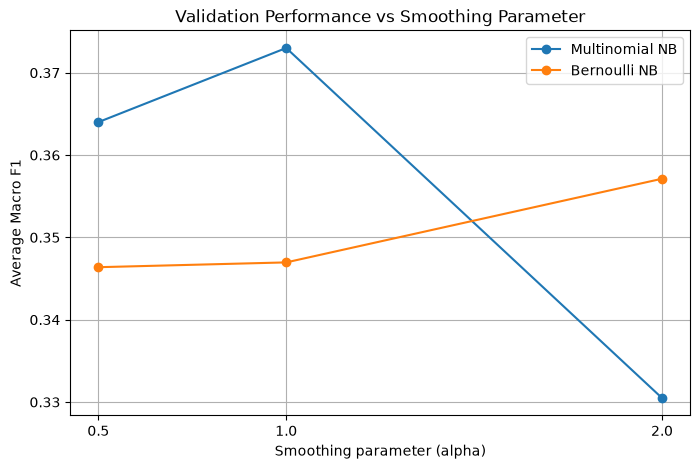

In [54]:
alphas = [
    result["alpha"]
    for result in multinomial_smoothing_results
]

multinomial_f1 = [
    result["macro_f1"]
    for result in multinomial_smoothing_results
]

bernoulli_f1 = [
    result["macro_f1"]
    for result in bernoulli_smoothing_results
]

plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    multinomial_f1,
    marker="o",
    label="Multinomial NB"
)

plt.plot(
    alphas,
    bernoulli_f1,
    marker="o",
    label="Bernoulli NB"
)

plt.xlabel("Smoothing parameter (alpha)")
plt.ylabel("Average Macro F1")
plt.title("Validation Performance vs Smoothing Parameter")
plt.xticks(alphas)
plt.legend()
plt.grid(True)

plt.show()

In [55]:
def log_scores_to_probabilities(scores):
    """
    Convert log-posterior scores into normalized probabilities
    using the numerically stable log-sum-exp technique.
    """

    labels = list(scores.keys())

    max_score = max(scores.values())

    exp_scores = {
        label: math.exp(scores[label] - max_score)
        for label in labels
    }

    total = sum(exp_scores.values())

    probabilities = {
        label: exp_scores[label] / total
        for label in labels
    }

    return probabilities

In [56]:
# Recreate Fold 1 preprocessing and model
test_indices = folds[0]

train_indices = np.concatenate(
    [folds[i] for i in range(len(folds)) if i != 0]
)

train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

train_tokens, test_tokens, vocabulary, binning_info = preprocess_train_test(
    train_df,
    test_df,
    n_bins=5
)

train_labels = train_df[TARGET].astype(int).tolist()

model = train_multinomial_nb(
    train_tokens,
    train_labels,
    vocabulary,
    alpha=1.0
)

# First held-out patient
actual_label = test_df[TARGET].iloc[0]

predicted_label, log_scores = predict_multinomial_nb(
    model,
    test_tokens[0]
)

probabilities = log_scores_to_probabilities(log_scores)

print("===== POSTERIOR PROBABILITIES =====")
print("Actual class    :", actual_label)
print("Predicted class :", predicted_label)

print("\nLog scores:")
for label in model["classes"]:
    print(f"Class {label}: {log_scores[label]:.6f}")

print("\nNormalized posterior probabilities:")
for label in model["classes"]:
    print(f"Class {label}: {probabilities[label]:.6f}")

print("\nProbability sum:", sum(probabilities.values()))

===== POSTERIOR PROBABILITIES =====
Actual class    : 2
Predicted class : 1

Log scores:
Class 0: -54.216467
Class 1: -48.018087
Class 2: -48.465381
Class 3: -48.107999
Class 4: -49.995785

Normalized posterior probabilities:
Class 0: 0.000755
Class 1: 0.371225
Class 2: 0.237345
Class 3: 0.339303
Class 4: 0.051373

Probability sum: 1.0


In [57]:
def calculate_multiclass_log_loss(
    actual_labels,
    probability_predictions,
    classes,
    epsilon=1e-15
):
    """
    Calculate multiclass log loss.

    probability_predictions is a list of dictionaries:
    {
        class_label: probability
    }
    """

    total_loss = 0.0

    for actual_label, probabilities in zip(
        actual_labels,
        probability_predictions
    ):
        true_probability = probabilities[actual_label]

        # Prevent log(0)
        true_probability = max(
            true_probability,
            epsilon
        )

        total_loss -= math.log(true_probability)

    return total_loss / len(actual_labels)

In [58]:
def run_probability_cv(
    df,
    folds,
    model_type,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
):
    all_actual = []
    all_probabilities = []
    fold_results = []

    for fold_number in range(len(folds)):

        test_indices = folds[fold_number]

        train_indices = np.concatenate(
            [
                folds[i]
                for i in range(len(folds))
                if i != fold_number
            ]
        )

        train_df = df.iloc[train_indices].copy()
        test_df = df.iloc[test_indices].copy()

        # Preprocessing is fitted only on training data
        if binning_strategy == "equal_width":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        elif binning_strategy == "quantile":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test_quantile(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        else:
            raise ValueError("Unknown binning strategy")

        train_labels = train_df[TARGET].astype(int).tolist()
        test_labels = test_df[TARGET].astype(int).tolist()

        # Train selected model
        if model_type == "multinomial":

            model = train_multinomial_nb(
                train_tokens,
                train_labels,
                vocabulary,
                alpha=alpha
            )

            prediction_function = predict_multinomial_nb

        elif model_type == "bernoulli":

            model = train_bernoulli_nb(
                train_tokens,
                train_labels,
                vocabulary,
                alpha=alpha
            )

            prediction_function = predict_bernoulli_nb

        else:
            raise ValueError(
                "model_type must be 'multinomial' or 'bernoulli'"
            )

        fold_probabilities = []

        for tokens in test_tokens:

            predicted_class, log_scores = prediction_function(
                model,
                tokens
            )

            probabilities = log_scores_to_probabilities(
                log_scores
            )

            fold_probabilities.append(probabilities)

        fold_log_loss = calculate_multiclass_log_loss(
            test_labels,
            fold_probabilities,
            model["classes"]
        )

        fold_results.append(
            {
                "fold": fold_number + 1,
                "log_loss": fold_log_loss
            }
        )

        all_actual.extend(test_labels)
        all_probabilities.extend(fold_probabilities)

    overall_log_loss = calculate_multiclass_log_loss(
        all_actual,
        all_probabilities,
        sorted(set(all_actual))
    )

    return {
        "fold_results": fold_results,
        "overall_log_loss": overall_log_loss,
        "actual_labels": all_actual,
        "probabilities": all_probabilities
    }

In [59]:
multinomial_probability_results = run_probability_cv(
    df,
    folds,
    model_type="multinomial",
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

bernoulli_probability_results = run_probability_cv(
    df,
    folds,
    model_type="bernoulli",
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== MULTINOMIAL NB: LOG LOSS =====")

for result in multinomial_probability_results["fold_results"]:
    print(
        f"Fold {result['fold']}: "
        f"Log Loss = {result['log_loss']:.4f}"
    )

print(
    f"\nOverall Multinomial Log Loss: "
    f"{multinomial_probability_results['overall_log_loss']:.4f}"
)


print("\n===== BERNOULLI NB: LOG LOSS =====")

for result in bernoulli_probability_results["fold_results"]:
    print(
        f"Fold {result['fold']}: "
        f"Log Loss = {result['log_loss']:.4f}"
    )

print(
    f"\nOverall Bernoulli Log Loss: "
    f"{bernoulli_probability_results['overall_log_loss']:.4f}"
)

===== MULTINOMIAL NB: LOG LOSS =====
Fold 1: Log Loss = 1.3543
Fold 2: Log Loss = 1.0420
Fold 3: Log Loss = 0.9949
Fold 4: Log Loss = 0.8968
Fold 5: Log Loss = 1.2052

Overall Multinomial Log Loss: 1.0994

===== BERNOULLI NB: LOG LOSS =====
Fold 1: Log Loss = 1.8877
Fold 2: Log Loss = 1.3951
Fold 3: Log Loss = 1.1550
Fold 4: Log Loss = 1.1514
Fold 5: Log Loss = 1.6393

Overall Bernoulli Log Loss: 1.4469


In [60]:
def build_reliability_data(actual_labels, probability_predictions):

    confidence_values = []
    correctness_values = []

    for actual_label, probabilities in zip(
        actual_labels,
        probability_predictions
    ):

        predicted_label = max(
            probabilities,
            key=probabilities.get
        )

        confidence = probabilities[predicted_label]

        correct = int(
            predicted_label == actual_label
        )

        confidence_values.append(confidence)
        correctness_values.append(correct)

    bins = np.linspace(0.0, 1.0, 11)

    mean_confidence = []
    accuracy = []
    counts = []

    for i in range(len(bins) - 1):

        lower = bins[i]
        upper = bins[i + 1]

        if i == len(bins) - 2:
            mask = [
                lower <= confidence <= upper
                for confidence in confidence_values
            ]
        else:
            mask = [
                lower <= confidence < upper
                for confidence in confidence_values
            ]

        selected_confidences = [
            confidence
            for confidence, include in zip(
                confidence_values,
                mask
            )
            if include
        ]

        selected_correctness = [
            correct
            for correct, include in zip(
                correctness_values,
                mask
            )
            if include
        ]

        if len(selected_confidences) > 0:

            mean_confidence.append(
                np.mean(selected_confidences)
            )

            accuracy.append(
                np.mean(selected_correctness)
            )

            counts.append(
                len(selected_confidences)
            )

    return mean_confidence, accuracy, counts

===== MULTINOMIAL CALIBRATION =====
Confidence = 0.272, Accuracy = 0.000, Samples = 1
Confidence = 0.355, Accuracy = 0.438, Samples = 16
Confidence = 0.449, Accuracy = 0.300, Samples = 40
Confidence = 0.544, Accuracy = 0.378, Samples = 45
Confidence = 0.654, Accuracy = 0.324, Samples = 34
Confidence = 0.751, Accuracy = 0.304, Samples = 23
Confidence = 0.846, Accuracy = 0.720, Samples = 25
Confidence = 0.970, Accuracy = 0.899, Samples = 119

===== BERNOULLI CALIBRATION =====
Confidence = 0.296, Accuracy = 0.000, Samples = 1
Confidence = 0.359, Accuracy = 0.400, Samples = 5
Confidence = 0.456, Accuracy = 0.300, Samples = 20
Confidence = 0.556, Accuracy = 0.360, Samples = 25
Confidence = 0.643, Accuracy = 0.302, Samples = 43
Confidence = 0.751, Accuracy = 0.333, Samples = 21
Confidence = 0.851, Accuracy = 0.341, Samples = 44
Confidence = 0.984, Accuracy = 0.847, Samples = 144


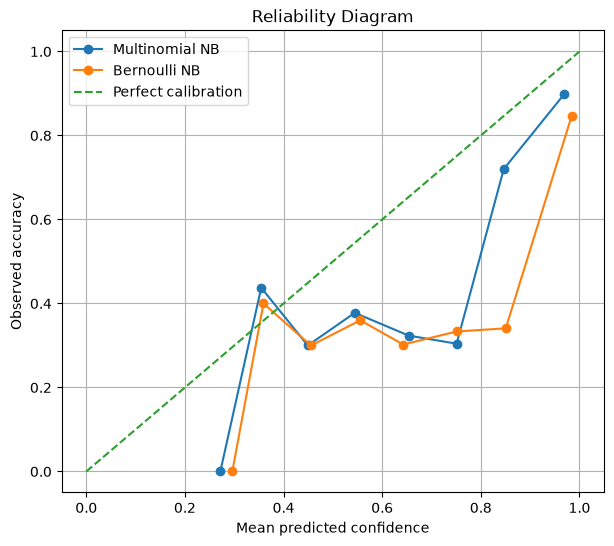

In [61]:
multinomial_confidence, multinomial_calibration_accuracy, multinomial_counts = (
    build_reliability_data(
        multinomial_probability_results["actual_labels"],
        multinomial_probability_results["probabilities"]
    )
)

bernoulli_confidence, bernoulli_calibration_accuracy, bernoulli_counts = (
    build_reliability_data(
        bernoulli_probability_results["actual_labels"],
        bernoulli_probability_results["probabilities"]
    )
)

print("===== MULTINOMIAL CALIBRATION =====")

for confidence, accuracy, count in zip(
    multinomial_confidence,
    multinomial_calibration_accuracy,
    multinomial_counts
):
    print(
        f"Confidence = {confidence:.3f}, "
        f"Accuracy = {accuracy:.3f}, "
        f"Samples = {count}"
    )

print("\n===== BERNOULLI CALIBRATION =====")

for confidence, accuracy, count in zip(
    bernoulli_confidence,
    bernoulli_calibration_accuracy,
    bernoulli_counts
):
    print(
        f"Confidence = {confidence:.3f}, "
        f"Accuracy = {accuracy:.3f}, "
        f"Samples = {count}"
    )


plt.figure(figsize=(7, 6))

plt.plot(
    multinomial_confidence,
    multinomial_calibration_accuracy,
    marker="o",
    label="Multinomial NB"
)

plt.plot(
    bernoulli_confidence,
    bernoulli_calibration_accuracy,
    marker="o",
    label="Bernoulli NB"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Reliability Diagram")
plt.legend()
plt.grid(True)

plt.show()

In [62]:
def shuffle_feature_value_tokens(
    token_lists,
    seed=42
):
    """
    Shuffle each feature-value token column across patients.

    The same feature remains in the same position, but its
    value/token is randomly reassigned between patients.
    """

    rng = np.random.default_rng(seed)

    shuffled_tokens = [
        tokens.copy()
        for tokens in token_lists
    ]

    if len(shuffled_tokens) == 0:
        return shuffled_tokens

    number_of_features = len(shuffled_tokens[0])

    for feature_index in range(number_of_features):

        values = [
            tokens[feature_index]
            for tokens in shuffled_tokens
        ]

        rng.shuffle(values)

        for patient_index in range(len(shuffled_tokens)):
            shuffled_tokens[patient_index][feature_index] = (
                values[patient_index]
            )

    return shuffled_tokens

In [63]:
def run_shuffled_token_cv(
    df,
    folds,
    model_type,
    seed=42,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
):
    fold_results = []

    for fold_number in range(len(folds)):

        test_indices = folds[fold_number]

        train_indices = np.concatenate(
            [
                folds[i]
                for i in range(len(folds))
                if i != fold_number
            ]
        )

        train_df = df.iloc[train_indices].copy()
        test_df = df.iloc[test_indices].copy()

        if binning_strategy == "equal_width":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        elif binning_strategy == "quantile":

            train_tokens, test_tokens, vocabulary, binning_info = (
                preprocess_train_test_quantile(
                    train_df,
                    test_df,
                    n_bins=n_bins
                )
            )

        else:
            raise ValueError("Unknown binning strategy")

        train_labels = train_df[TARGET].astype(int).tolist()
        test_labels = test_df[TARGET].astype(int).tolist()

        # Shuffle training feature-value assignments.
        shuffled_train_tokens = shuffle_feature_value_tokens(
            train_tokens,
            seed=seed
        )

        # Shuffle test feature-value assignments using a different
        # deterministic seed so patient-feature associations are destroyed.
        shuffled_test_tokens = shuffle_feature_value_tokens(
            test_tokens,
            seed=seed + 1
        )

        if model_type == "multinomial":

            model = train_multinomial_nb(
                shuffled_train_tokens,
                train_labels,
                vocabulary,
                alpha=alpha
            )

            predictions = [
                predict_multinomial_nb(
                    model,
                    tokens
                )[0]
                for tokens in shuffled_test_tokens
            ]

        elif model_type == "bernoulli":

            model = train_bernoulli_nb(
                shuffled_train_tokens,
                train_labels,
                vocabulary,
                alpha=alpha
            )

            predictions = [
                predict_bernoulli_nb(
                    model,
                    tokens
                )[0]
                for tokens in shuffled_test_tokens
            ]

        else:
            raise ValueError(
                "model_type must be 'multinomial' or 'bernoulli'"
            )

        metrics = calculate_metrics(
            test_labels,
            predictions,
            model["classes"]
        )

        fold_results.append(
            {
                "fold": fold_number + 1,
                "accuracy": metrics["accuracy"],
                "macro_f1": metrics["macro_f1"],
                "micro_f1": metrics["micro_f1"],
                "confusion_matrix": metrics["confusion_matrix"]
            }
        )

    return fold_results

In [64]:
shuffled_multinomial_results = run_shuffled_token_cv(
    df,
    folds,
    model_type="multinomial",
    seed=SEED,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

shuffled_bernoulli_results = run_shuffled_token_cv(
    df,
    folds,
    model_type="bernoulli",
    seed=SEED,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

print("===== SHUFFLED TOKENS: MULTINOMIAL NB =====")

for result in shuffled_multinomial_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

shuffled_multinomial_accuracy = np.mean(
    [r["accuracy"] for r in shuffled_multinomial_results]
)

shuffled_multinomial_macro_f1 = np.mean(
    [r["macro_f1"] for r in shuffled_multinomial_results]
)

print(f"\nAverage Accuracy : {shuffled_multinomial_accuracy:.4f}")
print(f"Average Macro F1 : {shuffled_multinomial_macro_f1:.4f}")


print("\n===== SHUFFLED TOKENS: BERNOULLI NB =====")

for result in shuffled_bernoulli_results:
    print(
        f"Fold {result['fold']}: "
        f"Accuracy = {result['accuracy']:.4f}, "
        f"Macro F1 = {result['macro_f1']:.4f}"
    )

shuffled_bernoulli_accuracy = np.mean(
    [r["accuracy"] for r in shuffled_bernoulli_results]
)

shuffled_bernoulli_macro_f1 = np.mean(
    [r["macro_f1"] for r in shuffled_bernoulli_results]
)

print(f"\nAverage Accuracy : {shuffled_bernoulli_accuracy:.4f}")
print(f"Average Macro F1 : {shuffled_bernoulli_macro_f1:.4f}")


print("\n===== PERFORMANCE CHANGE =====")

print(
    f"Multinomial Accuracy change: "
    f"{shuffled_multinomial_accuracy - empirical_accuracy:+.4f}"
)

print(
    f"Multinomial Macro F1 change: "
    f"{shuffled_multinomial_macro_f1 - empirical_macro_f1:+.4f}"
)

print(
    f"Bernoulli Accuracy change: "
    f"{shuffled_bernoulli_accuracy - np.mean([r['accuracy'] for r in run_bernoulli_cv(df, folds, 'equal_width', 5, 1.0)]):+.4f}"
)

print(
    f"Bernoulli Macro F1 change: "
    f"{shuffled_bernoulli_macro_f1 - np.mean([r['macro_f1'] for r in run_bernoulli_cv(df, folds, 'equal_width', 5, 1.0)]):+.4f}"
)

===== SHUFFLED TOKENS: MULTINOMIAL NB =====
Fold 1: Accuracy = 0.5000, Macro F1 = 0.1409
Fold 2: Accuracy = 0.4426, Macro F1 = 0.1286
Fold 3: Accuracy = 0.5410, Macro F1 = 0.1435
Fold 4: Accuracy = 0.5167, Macro F1 = 0.1425
Fold 5: Accuracy = 0.5254, Macro F1 = 0.2111

Average Accuracy : 0.5051
Average Macro F1 : 0.1533

===== SHUFFLED TOKENS: BERNOULLI NB =====
Fold 1: Accuracy = 0.4355, Macro F1 = 0.1317
Fold 2: Accuracy = 0.4262, Macro F1 = 0.1493
Fold 3: Accuracy = 0.4918, Macro F1 = 0.1672
Fold 4: Accuracy = 0.4167, Macro F1 = 0.1580
Fold 5: Accuracy = 0.4068, Macro F1 = 0.1461

Average Accuracy : 0.4354
Average Macro F1 : 0.1505

===== PERFORMANCE CHANGE =====
Multinomial Accuracy change: -0.0859
Multinomial Macro F1 change: -0.2197
Bernoulli Accuracy change: -0.1391
Bernoulli Macro F1 change: -0.1965


In [65]:
def calculate_binary_roc_curve(actual_binary, scores):

    thresholds = sorted(
        set(scores),
        reverse=True
    )

    thresholds = [float("inf")] + thresholds

    tpr = []
    fpr = []

    positive_count = sum(actual_binary)
    negative_count = len(actual_binary) - positive_count

    for threshold in thresholds:

        predictions = [
            1 if score >= threshold else 0
            for score in scores
        ]

        tp = sum(
            1
            for actual, predicted in zip(
                actual_binary,
                predictions
            )
            if actual == 1 and predicted == 1
        )

        fp = sum(
            1
            for actual, predicted in zip(
                actual_binary,
                predictions
            )
            if actual == 0 and predicted == 1
        )

        tpr.append(
            tp / positive_count
            if positive_count > 0 else 0.0
        )

        fpr.append(
            fp / negative_count
            if negative_count > 0 else 0.0
        )

    return fpr, tpr


def calculate_precision_recall_curve(
    actual_binary,
    scores
):

    thresholds = sorted(
        set(scores),
        reverse=True
    )

    thresholds = [float("inf")] + thresholds

    precision = []
    recall = []

    positive_count = sum(actual_binary)

    for threshold in thresholds:

        predictions = [
            1 if score >= threshold else 0
            for score in scores
        ]

        tp = sum(
            1
            for actual, predicted in zip(
                actual_binary,
                predictions
            )
            if actual == 1 and predicted == 1
        )

        fp = sum(
            1
            for actual, predicted in zip(
                actual_binary,
                predictions
            )
            if actual == 0 and predicted == 1
        )

        fn = sum(
            1
            for actual, predicted in zip(
                actual_binary,
                predictions
            )
            if actual == 1 and predicted == 0
        )

        precision.append(
            tp / (tp + fp)
            if tp + fp > 0 else 1.0
        )

        recall.append(
            tp / positive_count
            if positive_count > 0 else 0.0
        )

    return precision, recall

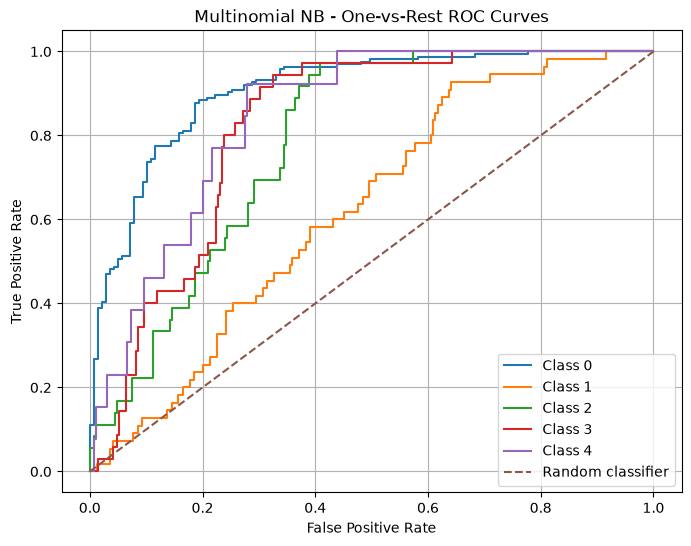

In [66]:
actual_labels = multinomial_probability_results["actual_labels"]
probabilities = multinomial_probability_results["probabilities"]

classes = sorted(set(actual_labels))

plt.figure(figsize=(8, 6))

for class_label in classes:

    actual_binary = [
        1 if actual == class_label else 0
        for actual in actual_labels
    ]

    scores = [
        probability[class_label]
        for probability in probabilities
    ]

    fpr, tpr = calculate_binary_roc_curve(
        actual_binary,
        scores
    )

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_label}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multinomial NB - One-vs-Rest ROC Curves")
plt.legend()
plt.grid(True)

plt.show()

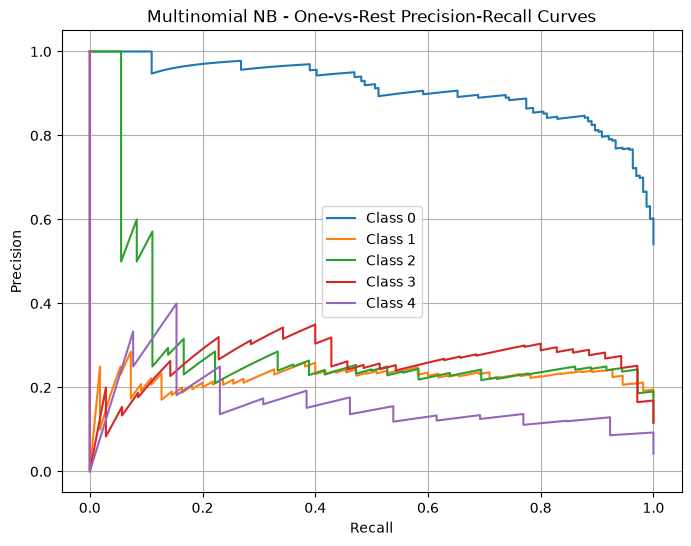

In [67]:
plt.figure(figsize=(8, 6))

for class_label in classes:

    actual_binary = [
        1 if actual == class_label else 0
        for actual in actual_labels
    ]

    scores = [
        probability[class_label]
        for probability in probabilities
    ]

    precision, recall = calculate_precision_recall_curve(
        actual_binary,
        scores
    )

    plt.plot(
        recall,
        precision,
        label=f"Class {class_label}"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Multinomial NB - One-vs-Rest Precision-Recall Curves")
plt.legend()
plt.grid(True)

plt.show()

In [68]:
final_results = pd.DataFrame([
    {
        "Model": "Multinomial NB",
        "Binning": "Equal-width",
        "Classes": "5",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.5910,
        "Macro F1": 0.3730
    },
    {
        "Model": "Bernoulli NB",
        "Binning": "Equal-width",
        "Classes": "5",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.5745,
        "Macro F1": 0.3470
    },
    {
        "Model": "Multinomial NB",
        "Binning": "Quantile",
        "Classes": "5",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.5611,
        "Macro F1": 0.3040
    },
    {
        "Model": "Bernoulli NB",
        "Binning": "Quantile",
        "Classes": "5",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.5711,
        "Macro F1": 0.3456
    },
    {
        "Model": "Multinomial NB",
        "Binning": "Equal-width",
        "Classes": "Binary",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.8285,
        "Macro F1": 0.8270
    },
    {
        "Model": "Bernoulli NB",
        "Binning": "Equal-width",
        "Classes": "Binary",
        "Missing": "Explicit token",
        "Alpha": 1.0,
        "Accuracy": 0.8351,
        "Macro F1": 0.8339
    },
    {
        "Model": "Multinomial NB",
        "Binning": "Equal-width",
        "Classes": "5",
        "Missing": "Remove incomplete",
        "Alpha": 1.0,
        "Accuracy": 0.5551,
        "Macro F1": 0.3039
    },
    {
        "Model": "Bernoulli NB",
        "Binning": "Equal-width",
        "Classes": "5",
        "Missing": "Remove incomplete",
        "Alpha": 1.0,
        "Accuracy": 0.5553,
        "Macro F1": 0.3106
    }
])

print(final_results.to_string(index=False))

         Model     Binning Classes           Missing  Alpha  Accuracy  Macro F1
Multinomial NB Equal-width       5    Explicit token    1.0    0.5910    0.3730
  Bernoulli NB Equal-width       5    Explicit token    1.0    0.5745    0.3470
Multinomial NB    Quantile       5    Explicit token    1.0    0.5611    0.3040
  Bernoulli NB    Quantile       5    Explicit token    1.0    0.5711    0.3456
Multinomial NB Equal-width  Binary    Explicit token    1.0    0.8285    0.8270
  Bernoulli NB Equal-width  Binary    Explicit token    1.0    0.8351    0.8339
Multinomial NB Equal-width       5 Remove incomplete    1.0    0.5551    0.3039
  Bernoulli NB Equal-width       5 Remove incomplete    1.0    0.5553    0.3106


In [69]:
# Re-run the main 5-class equal-width experiments so that the
# fold-by-fold results are available for the final report.

multinomial_equal_results = run_multinomial_cv(
    df,
    folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)

bernoulli_equal_results = run_bernoulli_cv(
    df,
    folds,
    binning_strategy="equal_width",
    n_bins=5,
    alpha=1.0
)


print("===== MULTINOMIAL NB — 5-CLASS — EQUAL-WIDTH =====")

for i, result in enumerate(multinomial_equal_results, start=1):
    print(f"\nFold {i}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Macro F1 :", round(result["macro_f1"], 4))
    print(result["confusion_matrix"])


print("\n\n===== BERNOULLI NB — 5-CLASS — EQUAL-WIDTH =====")

for i, result in enumerate(bernoulli_equal_results, start=1):
    print(f"\nFold {i}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Macro F1 :", round(result["macro_f1"], 4))
    print(result["confusion_matrix"])

===== MULTINOMIAL NB — 5-CLASS — EQUAL-WIDTH =====

Fold 1
Accuracy: 0.5161
Macro F1 : 0.3014
[[26  5  1  0  1]
 [ 8  2  0  1  0]
 [ 1  4  1  2  0]
 [ 0  2  2  3  0]
 [ 0  1  1  1  0]]

Fold 2
Accuracy: 0.5902
Macro F1 : 0.3786
[[30  3  0  0  0]
 [ 4  2  2  3  0]
 [ 0  3  2  2  0]
 [ 1  0  4  1  1]
 [ 0  0  0  2  1]]

Fold 3
Accuracy: 0.6393
Macro F1 : 0.4834
[[30  2  1  0  0]
 [ 6  2  2  1  0]
 [ 0  2  3  2  0]
 [ 0  3  1  3  0]
 [ 0  1  0  1  1]]

Fold 4
Accuracy: 0.65
Macro F1 : 0.4168
[[30  2  1  0  0]
 [ 4  3  4  0  0]
 [ 0  4  3  0  0]
 [ 0  1  3  3  0]
 [ 0  1  1  0  0]]

Fold 5
Accuracy: 0.5593
Macro F1 : 0.2848
[[28  2  2  0  0]
 [ 3  3  3  2  0]
 [ 0  2  1  3  1]
 [ 0  4  2  1  0]
 [ 1  0  0  1  0]]


===== BERNOULLI NB — 5-CLASS — EQUAL-WIDTH =====

Fold 1
Accuracy: 0.5
Macro F1 : 0.2772
[[26  5  1  0  1]
 [ 8  2  0  1  0]
 [ 1  4  1  2  0]
 [ 0  2  2  2  1]
 [ 0  1  1  1  0]]

Fold 2
Accuracy: 0.5902
Macro F1 : 0.3929
[[29  4  0  0  0]
 [ 3  3  2  3  0]
 [ 0  3  2  2  0]
 [

In [70]:
summary_rows = []

for model_name, results in [
    ("Multinomial NB", multinomial_equal_results),
    ("Bernoulli NB", bernoulli_equal_results)
]:
    for fold_number, result in enumerate(results, start=1):
        summary_rows.append({
            "Model": model_name,
            "Fold": fold_number,
            "Accuracy": result["accuracy"],
            "Macro F1": result["macro_f1"],
            "Micro F1": result["micro_f1"]
        })

fold_summary = pd.DataFrame(summary_rows)

print(fold_summary.to_string(index=False))

print("\n===== AVERAGE =====")

average_summary = fold_summary.groupby("Model")[[
    "Accuracy", "Macro F1", "Micro F1"
]].mean()

print(average_summary.round(4))

         Model  Fold  Accuracy  Macro F1  Micro F1
Multinomial NB     1  0.516129  0.301425  0.516129
Multinomial NB     2  0.590164  0.378576  0.590164
Multinomial NB     3  0.639344  0.483437  0.639344
Multinomial NB     4  0.650000  0.416808  0.650000
Multinomial NB     5  0.559322  0.284784  0.559322
  Bernoulli NB     1  0.500000  0.277249  0.500000
  Bernoulli NB     2  0.590164  0.392900  0.590164
  Bernoulli NB     3  0.606557  0.351268  0.606557
  Bernoulli NB     4  0.633333  0.423364  0.633333
  Bernoulli NB     5  0.542373  0.290028  0.542373

===== AVERAGE =====
                Accuracy  Macro F1  Micro F1
Model                                       
Bernoulli NB      0.5745     0.347    0.5745
Multinomial NB    0.5910     0.373    0.5910


In [71]:
# Recreate Fold 1 so we can inspect individual validation patients.

train_indices = np.concatenate(folds[1:])
test_indices = folds[0]

train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

train_tokens, test_tokens, vocabulary, binning_info = preprocess_train_test(
    train_df,
    test_df,
    n_bins=5
)

train_labels = df.iloc[train_indices][TARGET].astype(int).tolist()
test_labels = df.iloc[test_indices][TARGET].astype(int).tolist()

model = train_multinomial_nb(
    train_tokens,
    train_labels,
    vocabulary,
    alpha=1.0
)

predictions = []

for tokens in test_tokens:
    predicted_class, scores = predict_multinomial_nb(model, tokens)
    predictions.append(predicted_class)

# Find one correctly classified and one misclassified patient
correct_position = None
wrong_position = None

for i, (actual, predicted) in enumerate(zip(test_labels, predictions)):
    if actual == predicted and correct_position is None:
        correct_position = i
    if actual != predicted and wrong_position is None:
        wrong_position = i

def print_patient_posterior(position, description):
    actual = test_labels[position]
    predicted, scores = predict_multinomial_nb(
        model,
        test_tokens[position]
    )
    probabilities = log_scores_to_probabilities(scores)

    patient_index = test_indices[position]

    print("\n" + "=" * 60)
    print(description)
    print("Patient dataset index:", patient_index)
    print("Actual class:", actual)
    print("Predicted class:", predicted)

    print("\nLog-posterior scores:")
    for label in sorted(scores):
        print(f"Class {label}: {scores[label]:.6f}")

    print("\nNormalized posterior probabilities:")
    for label in sorted(probabilities):
        print(f"Class {label}: {probabilities[label]:.6f}")

    print("\nProbability sum:",
          round(sum(probabilities.values()), 6))


print_patient_posterior(
    correct_position,
    "CORRECTLY CLASSIFIED VALIDATION PATIENT"
)

print_patient_posterior(
    wrong_position,
    "MISCLASSIFIED VALIDATION PATIENT"
)


CORRECTLY CLASSIFIED VALIDATION PATIENT
Patient dataset index: 13
Actual class: 0
Predicted class: 0

Log-posterior scores:
Class 0: -42.773153
Class 1: -46.053693
Class 2: -50.396230
Class 3: -49.143999
Class 4: -54.094583

Normalized posterior probabilities:
Class 0: 0.961705
Class 1: 0.036168
Class 2: 0.000470
Class 3: 0.001645
Class 4: 0.000012

Probability sum: 1.0

MISCLASSIFIED VALIDATION PATIENT
Patient dataset index: 1
Actual class: 2
Predicted class: 1

Log-posterior scores:
Class 0: -54.216467
Class 1: -48.018087
Class 2: -48.465381
Class 3: -48.107999
Class 4: -49.995785

Normalized posterior probabilities:
Class 0: 0.000755
Class 1: 0.371225
Class 2: 0.237345
Class 3: 0.339303
Class 4: 0.051373

Probability sum: 1.0


In [72]:
print("Pandas version:", pd.__version__)

Pandas version: 3.0.5


In [73]:
print("===== TASK 1: MODEL DETAILS =====")

print("\nMULTINOMIAL NAIVE BAYES")
print("-" * 40)

print("Vocabulary size: 50")
print("Alpha (Laplace smoothing): 1.0")

print("\nClass priors:")
print("Class 0: 0.543568")
print("Class 1: 0.182573")
print("Class 2: 0.116183")
print("Class 3: 0.116183")
print("Class 4: 0.041494")

print("\nSmoothing formula:")
print("P(token | class) = (count(token, class) + alpha)")
print("                  / (total tokens in class + alpha * |V|)")

print("\nLog-posterior:")
print("log P(class | patient) proportional to")
print("log P(class) + sum(log P(token | class))")


print("\n\nBERNOULLI NAIVE BAYES")
print("-" * 40)

print("Vocabulary size: 50")
print("Alpha (Laplace smoothing): 1.0")

print("\nClass priors:")
print("Class 0: 0.543568")
print("Class 1: 0.182573")
print("Class 2: 0.116183")
print("Class 3: 0.116183")
print("Class 4: 0.041494")

print("\nSmoothing formula:")
print("P(token present | class) =")
print("(present_count + alpha) / (class_count + 2 * alpha)")

print("\nLog-posterior:")
print("log P(class | patient) proportional to")
print("log P(class)")
print("+ sum over all vocabulary tokens:")
print("  log P(token | class)       if token is present")
print("  log(1 - P(token | class)) if token is absent")

print("\nTie-breaking rule:")
print("If scores are equal, choose the smaller class label.")

===== TASK 1: MODEL DETAILS =====

MULTINOMIAL NAIVE BAYES
----------------------------------------
Vocabulary size: 50
Alpha (Laplace smoothing): 1.0

Class priors:
Class 0: 0.543568
Class 1: 0.182573
Class 2: 0.116183
Class 3: 0.116183
Class 4: 0.041494

Smoothing formula:
P(token | class) = (count(token, class) + alpha)
                  / (total tokens in class + alpha * |V|)

Log-posterior:
log P(class | patient) proportional to
log P(class) + sum(log P(token | class))


BERNOULLI NAIVE BAYES
----------------------------------------
Vocabulary size: 50
Alpha (Laplace smoothing): 1.0

Class priors:
Class 0: 0.543568
Class 1: 0.182573
Class 2: 0.116183
Class 3: 0.116183
Class 4: 0.041494

Smoothing formula:
P(token present | class) =
(present_count + alpha) / (class_count + 2 * alpha)

Log-posterior:
log P(class | patient) proportional to
log P(class)
+ sum over all vocabulary tokens:
  log P(token | class)       if token is present
  log(1 - P(token | class)) if token is absent

Ti